Frequency spacing Δf = 0.095367 kHz
Frequency uncertainty u(f) = Δf/2 = 0.047684 kHz


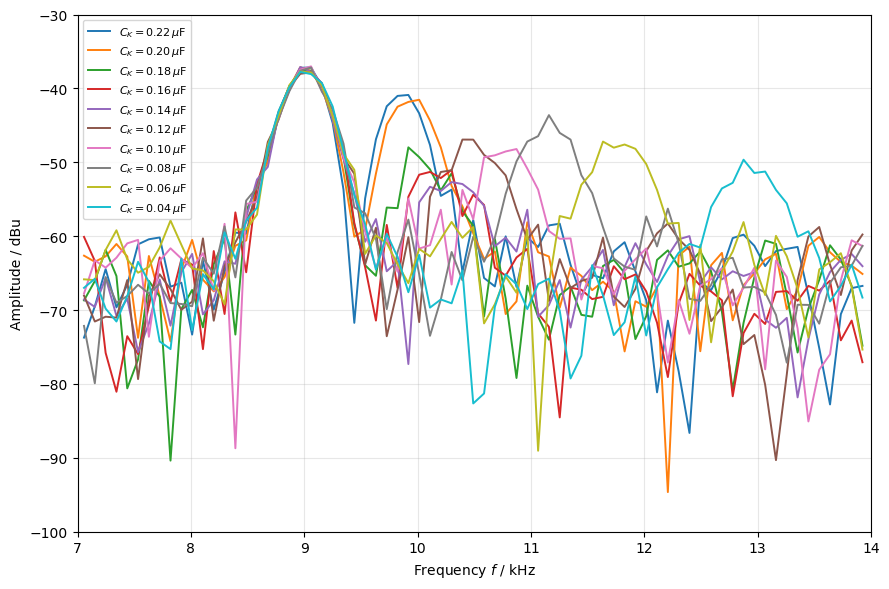

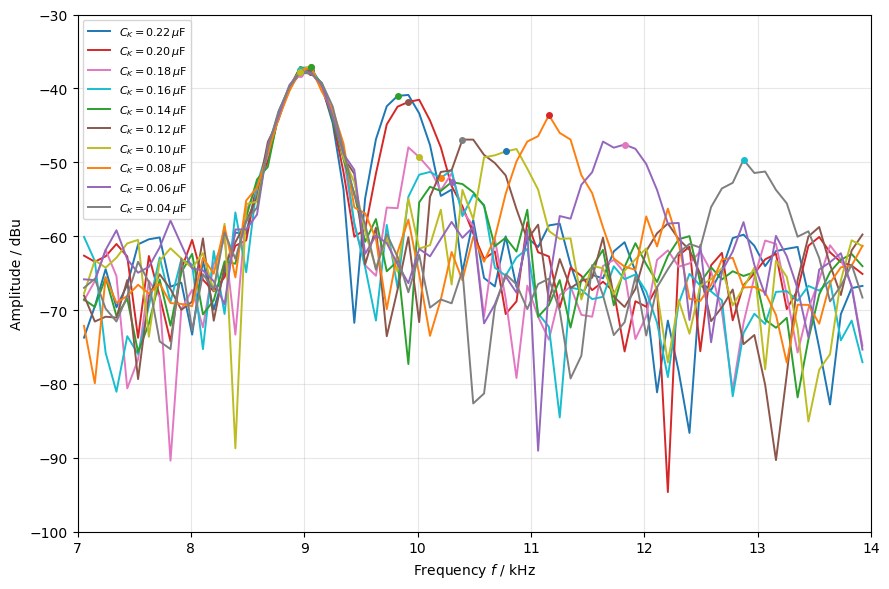


Low-point fit result:
C = (0.022000 ± 0.000000) microfarad
C = (22.000 ± 0.000) nF


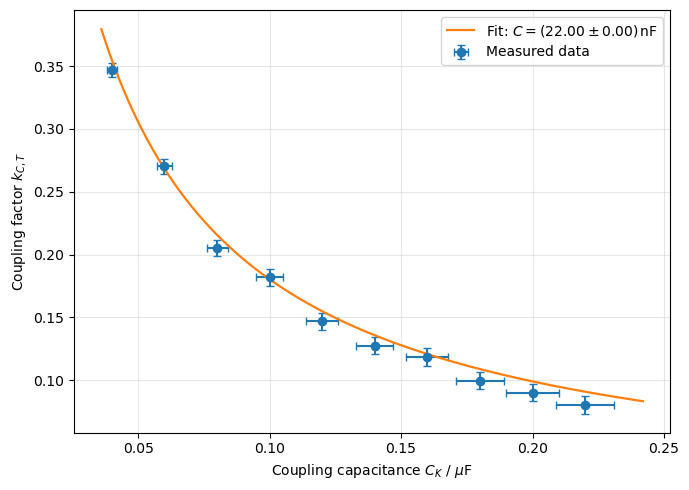

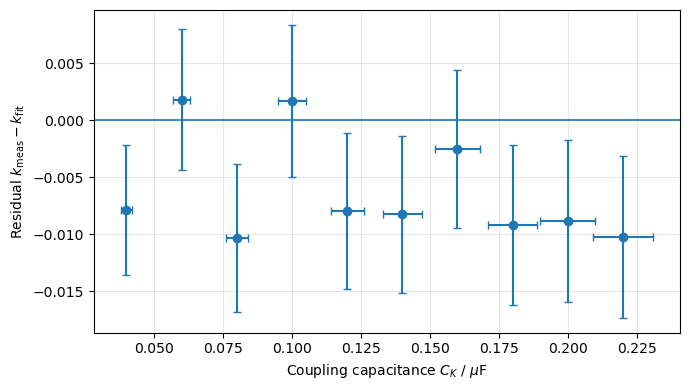


Task 1 summary
--------------
Frequency spacing Δf = 0.095367 kHz
Frequency uncertainty u(f) = Δf/2 = 0.047684 kHz
Coupling-capacitor uncertainty: u(C_K) = 5% of C_K
Fitted capacitance from low-point circuit:
C = (0.022000 ± 0.000000) microfarad
C = (22.000 ± 0.000) nF

Extracted peak table:


,file,Ck_uF,u_Ck_uF,f1_kHz,u_f1_kHz,f2_kHz,u_f2_kHz,k_CT,u_k_CT,k_fit,residual
0,S10.csv,0.22,0.011,9.0599,0.0477,9.8228,0.0477,0.0807,0.0071,0.0909,-0.0102
1,S11.csv,0.20,0.010,9.0599,0.0477,9.9182,0.0477,0.0903,0.0071,0.0991,-0.0088
2,S12.csv,0.18,0.009,9.0599,0.0477,10.0136,0.0477,0.0998,0.0070,0.1089,-0.0092
3,S13.csv,0.16,0.008,9.0599,0.0477,10.2043,0.0477,0.1184,0.0069,0.1209,-0.0025
4,S14.csv,0.14,0.007,9.0599,0.0477,10.2997,0.0477,0.1276,0.0069,0.1358,-0.0082
5,S15.csv,0.12,0.006,8.9645,0.0477,10.3951,0.0477,0.1470,0.0069,0.1549,-0.0079
6,S16.csv,0.10,0.005,8.9645,0.0477,10.7765,0.0477,0.1820,0.0067,0.1803,0.0017
7,S17.csv,0.08,0.004,9.0599,0.0477,11.1580,0.0477,0.2053,0.0065,0.2157,-0.0104
8,S18.csv,0.06,0.003,8.9645,0.0477,11.8256,0.0477,0.2701,0.0062,0.2683,0.0018
9,S19.csv,0.04,0.002,8.9645,0.0477,12.8746,0.0477,0.3470,0.0057,0.3548,-0.0079



Saved files:
task1_outputs\task1_low_point_all_spectra.png
task1_outputs\task1_low_point_peak_check.png
task1_outputs\task1_low_point_coupling_fit.png
task1_outputs\task1_low_point_fit_residuals.png
task1_outputs\task1_low_point_results.csv
task1_outputs\task1_low_point_report_table.csv
task1_outputs\task1_low_point_report_table.tex


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter
from scipy.odr import ODR, Model, RealData
from IPython.display import display

# -----------------------------
# 1. User settings
# -----------------------------

DATA_DIR = "."          # change this if your CSV files are in another folder
OUTPUT_DIR = "task1_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

files = [
    "S10.csv", "S11.csv", "S12.csv", "S13.csv", "S14.csv",
    "S15.csv", "S16.csv", "S17.csv", "S18.csv", "S19.csv"
]

# Coupling capacitor values in microfarad
Ck_uF = np.array([0.22, 0.20, 0.18, 0.16, 0.14, 0.12, 0.10, 0.08, 0.06, 0.04])

# 5% uncertainty in C_K
u_Ck_uF = 0.05 * Ck_uF

# Frequency ranges in kHz
PEAK_REGION_KHZ = (7.0, 14.0)
PLOT_REGION_KHZ = (7.0, 14.0)

# Manual peak override if needed:
# Example: manual_peaks_kHz = {"S10.csv": (9.05, 10.10)}
manual_peaks_kHz = {}

# -----------------------------
# 2. Read PicoScope CSV files
# -----------------------------

def read_picoscope_spectrum(path):
    """
    Reads PicoScope spectrum CSV with:
    Frequency;Channel A
    (kHz);(dBu)
    and decimal commas.
    """
    df = pd.read_csv(path, sep=";", skiprows=[1], decimal=",")
    df.columns = ["frequency_kHz", "amplitude_dBu"]
    df = df.dropna()
    df["frequency_kHz"] = pd.to_numeric(df["frequency_kHz"], errors="coerce")
    df["amplitude_dBu"] = pd.to_numeric(df["amplitude_dBu"], errors="coerce")
    df = df.dropna()
    return df

spectra = {}
for file in files:
    path = os.path.join(DATA_DIR, file)
    spectra[file] = read_picoscope_spectrum(path)

# Frequency spacing and uncertainty
freq_values = spectra[files[0]]["frequency_kHz"].values
delta_f_kHz = np.mean(np.diff(freq_values))
u_f_kHz = delta_f_kHz / 2.0

print(f"Frequency spacing Δf = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_kHz:.6f} kHz")

# -----------------------------
# 3. Combined spectrum plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_kHz"] >= PLOT_REGION_KHZ[0]) &
        (df["frequency_kHz"] <= PLOT_REGION_KHZ[1])
    )

    x_plot = df.loc[mask, "frequency_kHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    label = rf"$C_K={Ck_uF[i]:.2f}\,\mu\mathrm{{F}}$"
    plt.plot(x_plot, y_plot, linewidth=1.4, label=label)

plt.xlabel(r"Frequency $f$ / kHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(7, 14)
plt.ylim(-100, -30)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_low_point_all_spectra.png"), dpi=300)
plt.show()

# -----------------------------
# 4. Peak extraction
# -----------------------------

def extract_two_main_peaks(df, file):
    """
    Extracts the two dominant peaks in the expected frequency region.
    Uses Savitzky-Golay smoothing before peak finding.
    """
    if file in manual_peaks_kHz:
        f1, f2 = manual_peaks_kHz[file]
        return float(f1), float(f2)

    mask = (
        (df["frequency_kHz"] >= PEAK_REGION_KHZ[0]) &
        (df["frequency_kHz"] <= PEAK_REGION_KHZ[1])
    )

    x = df.loc[mask, "frequency_kHz"].values
    y = df.loc[mask, "amplitude_dBu"].values

    window_length = 9
    if window_length >= len(y):
        window_length = len(y) - 1 if len(y) % 2 == 0 else len(y)
    if window_length < 5:
        window_length = 5
    if window_length % 2 == 0:
        window_length += 1

    y_smooth = savgol_filter(y, window_length=window_length, polyorder=3)

    min_distance_kHz = 0.40
    min_distance_bins = max(1, int(min_distance_kHz / delta_f_kHz))

    peaks, _ = find_peaks(
        y_smooth,
        prominence=1.0,
        distance=min_distance_bins
    )

    if len(peaks) < 2:
        raise RuntimeError(
            f"Less than two peaks found in {file}. "
            "Adjust PEAK_REGION_KHZ/prominence or set manual_peaks_kHz."
        )

    selected = sorted(peaks, key=lambda idx: y_smooth[idx], reverse=True)[:2]
    selected_freqs = np.sort(x[selected])

    return selected_freqs[0], selected_freqs[1]

peak_rows = []

for i, file in enumerate(files):
    df = spectra[file]
    f1_kHz, f2_kHz = extract_two_main_peaks(df, file)

    peak_rows.append({
        "file": file,
        "Ck_uF": Ck_uF[i],
        "u_Ck_uF": u_Ck_uF[i],
        "f1_kHz": f1_kHz,
        "u_f1_kHz": u_f_kHz,
        "f2_kHz": f2_kHz,
        "u_f2_kHz": u_f_kHz
    })

task1_df = pd.DataFrame(peak_rows)

# -----------------------------
# 5. Peak-check plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_kHz"] >= PLOT_REGION_KHZ[0]) &
        (df["frequency_kHz"] <= PLOT_REGION_KHZ[1])
    )

    x_plot = df.loc[mask, "frequency_kHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    plt.plot(
        x_plot,
        y_plot,
        linewidth=1.4,
        label=rf"$C_K={Ck_uF[i]:.2f}\,\mu\mathrm{{F}}$"
    )

    f1 = task1_df.loc[i, "f1_kHz"]
    f2 = task1_df.loc[i, "f2_kHz"]

    y1 = np.interp(f1, x_plot, y_plot)
    y2 = np.interp(f2, x_plot, y_plot)

    plt.plot(f1, y1, marker="o", markersize=4)
    plt.plot(f2, y2, marker="o", markersize=4)

plt.xlabel(r"Frequency $f$ / kHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(7, 14)
plt.ylim(-100, -30)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_low_point_peak_check.png"), dpi=300)
plt.show()

# -----------------------------
# 6. Coupling factor and uncertainty
# -----------------------------

def coupling_factor(f1, f2):
    """
    k = |(f1^2 - f2^2)/(f1^2 + f2^2)|
    """
    return np.abs((f1**2 - f2**2) / (f1**2 + f2**2))

def coupling_factor_uncertainty(f1, f2, u_f1, u_f2):
    """
    Gaussian uncertainty propagation for:
    k = (f2^2 - f1^2)/(f2^2 + f1^2), assuming f2 > f1
    """
    denominator = (f1**2 + f2**2)**2
    dk_df1 = -4.0 * f1 * f2**2 / denominator
    dk_df2 =  4.0 * f2 * f1**2 / denominator
    return np.sqrt((dk_df1 * u_f1)**2 + (dk_df2 * u_f2)**2)

task1_df["k_CT"] = coupling_factor(
    task1_df["f1_kHz"].values,
    task1_df["f2_kHz"].values
)

task1_df["u_k_CT"] = coupling_factor_uncertainty(
    task1_df["f1_kHz"].values,
    task1_df["f2_kHz"].values,
    task1_df["u_f1_kHz"].values,
    task1_df["u_f2_kHz"].values
)

# Frequencies also in Hz
task1_df["f1_Hz"] = task1_df["f1_kHz"] * 1000.0
task1_df["u_f1_Hz"] = task1_df["u_f1_kHz"] * 1000.0
task1_df["f2_Hz"] = task1_df["f2_kHz"] * 1000.0
task1_df["u_f2_Hz"] = task1_df["u_f2_kHz"] * 1000.0

# -----------------------------
# 7. Fit low-point model
# -----------------------------
# Model: k_CT(C_K) = C / (C + C_K)
# Both C and C_K in microfarad

def low_point_model_odr(beta, x):
    C_uF = beta[0]
    return C_uF / (C_uF + x)

x = task1_df["Ck_uF"].values
y = task1_df["k_CT"].values
sx = task1_df["u_Ck_uF"].values
sy = task1_df["u_k_CT"].values

model = Model(low_point_model_odr)
data = RealData(x, y, sx=sx, sy=sy)

odr = ODR(data, model, beta0=[0.022])   # initial guess
fit_output = odr.run()

C_fit_uF = fit_output.beta[0]
u_C_fit_uF = fit_output.sd_beta[0]

C_fit_nF = C_fit_uF * 1000.0
u_C_fit_nF = u_C_fit_uF * 1000.0

task1_df["k_fit"] = low_point_model_odr([C_fit_uF], x)
task1_df["residual"] = task1_df["k_CT"] - task1_df["k_fit"]

print("\nLow-point fit result:")
print(f"C = ({C_fit_uF:.6f} ± {u_C_fit_uF:.6f}) microfarad")
print(f"C = ({C_fit_nF:.3f} ± {u_C_fit_nF:.3f}) nF")

# -----------------------------
# 8. Coupling-factor plot with fit
# -----------------------------

Ck_fit = np.linspace(min(Ck_uF) * 0.9, max(Ck_uF) * 1.1, 500)
k_fit = low_point_model_odr([C_fit_uF], Ck_fit)

plt.figure(figsize=(7, 5))

plt.errorbar(
    task1_df["Ck_uF"],
    task1_df["k_CT"],
    xerr=task1_df["u_Ck_uF"],
    yerr=task1_df["u_k_CT"],
    fmt="o",
    capsize=3,
    label="Measured data"
)

plt.plot(
    Ck_fit,
    k_fit,
    linewidth=1.6,
    label=rf"Fit: $C=({C_fit_nF:.2f}\pm{u_C_fit_nF:.2f})\,\mathrm{{nF}}$"
)

plt.xlabel(r"Coupling capacitance $C_K$ / $\mu\mathrm{F}$")
plt.ylabel(r"Coupling factor $k_{C,T}$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_low_point_coupling_fit.png"), dpi=300)
plt.show()

# -----------------------------
# 9. Residual plot
# -----------------------------

plt.figure(figsize=(7, 4))

plt.errorbar(
    task1_df["Ck_uF"],
    task1_df["residual"],
    xerr=task1_df["u_Ck_uF"],
    yerr=task1_df["u_k_CT"],
    fmt="o",
    capsize=3
)

plt.axhline(0, linewidth=1.2)

plt.xlabel(r"Coupling capacitance $C_K$ / $\mu\mathrm{F}$")
plt.ylabel(r"Residual $k_{\mathrm{meas}}-k_{\mathrm{fit}}$")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task1_low_point_fit_residuals.png"), dpi=300)
plt.show()

# -----------------------------
# 10. Save result tables
# -----------------------------

task1_df = task1_df[
    [
        "file",
        "Ck_uF", "u_Ck_uF",
        "f1_kHz", "u_f1_kHz",
        "f2_kHz", "u_f2_kHz",
        "k_CT", "u_k_CT",
        "k_fit", "residual",
        "f1_Hz", "u_f1_Hz",
        "f2_Hz", "u_f2_Hz"
    ]
]

task1_df.to_csv(os.path.join(OUTPUT_DIR, "task1_low_point_results.csv"), index=False)

report_table = task1_df.copy()
report_table["Ck_uF"] = report_table["Ck_uF"].round(3)
report_table["u_Ck_uF"] = report_table["u_Ck_uF"].round(3)
report_table["f1_kHz"] = report_table["f1_kHz"].round(4)
report_table["u_f1_kHz"] = report_table["u_f1_kHz"].round(4)
report_table["f2_kHz"] = report_table["f2_kHz"].round(4)
report_table["u_f2_kHz"] = report_table["u_f2_kHz"].round(4)
report_table["k_CT"] = report_table["k_CT"].round(4)
report_table["u_k_CT"] = report_table["u_k_CT"].round(4)
report_table["k_fit"] = report_table["k_fit"].round(4)
report_table["residual"] = report_table["residual"].round(4)

report_table = report_table[
    [
        "file",
        "Ck_uF", "u_Ck_uF",
        "f1_kHz", "u_f1_kHz",
        "f2_kHz", "u_f2_kHz",
        "k_CT", "u_k_CT",
        "k_fit", "residual"
    ]
]

report_table.to_csv(os.path.join(OUTPUT_DIR, "task1_low_point_report_table.csv"), index=False)

latex_table = report_table.to_latex(
    index=False,
    escape=False,
    column_format="lrrrrrrrrrr"
)

with open(os.path.join(OUTPUT_DIR, "task1_low_point_report_table.tex"), "w") as f:
    f.write(latex_table)

# -----------------------------
# 11. Print summary
# -----------------------------

print("\nTask 1 summary")
print("--------------")
print(f"Frequency spacing Δf = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_kHz:.6f} kHz")
print("Coupling-capacitor uncertainty: u(C_K) = 5% of C_K")
print(f"Fitted capacitance from low-point circuit:")
print(f"C = ({C_fit_uF:.6f} ± {u_C_fit_uF:.6f}) microfarad")
print(f"C = ({C_fit_nF:.3f} ± {u_C_fit_nF:.3f}) nF")

print("\nExtracted peak table:")
display(report_table)

print("\nSaved files:")
for filename in [
    "task1_low_point_all_spectra.png",
    "task1_low_point_peak_check.png",
    "task1_low_point_coupling_fit.png",
    "task1_low_point_fit_residuals.png",
    "task1_low_point_results.csv",
    "task1_low_point_report_table.csv",
    "task1_low_point_report_table.tex"
]:
    print(os.path.join(OUTPUT_DIR, filename))

Frequency spacing Δf = 0.00038147 MHz = 0.381470 kHz
Frequency uncertainty u(f) = Δf/2 = 0.00019073 MHz = 0.190735 kHz


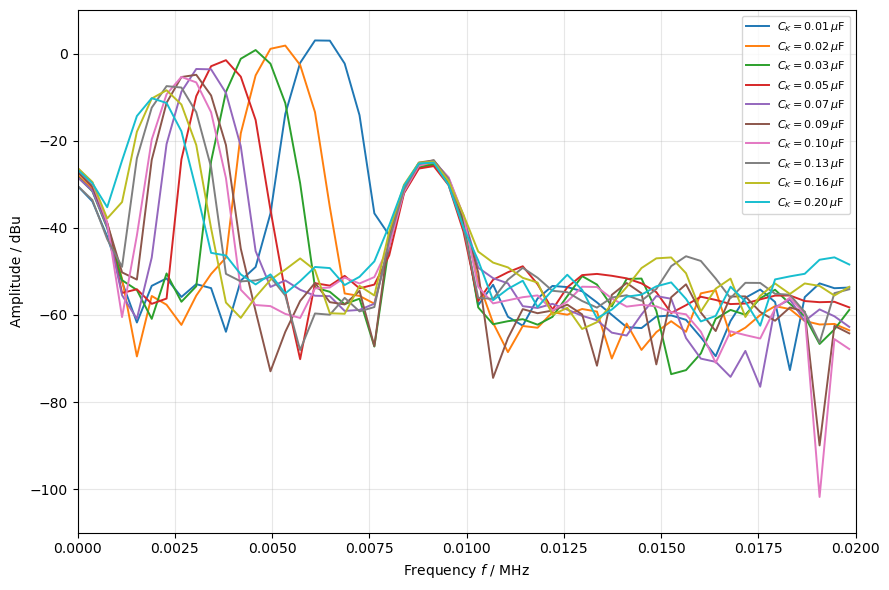

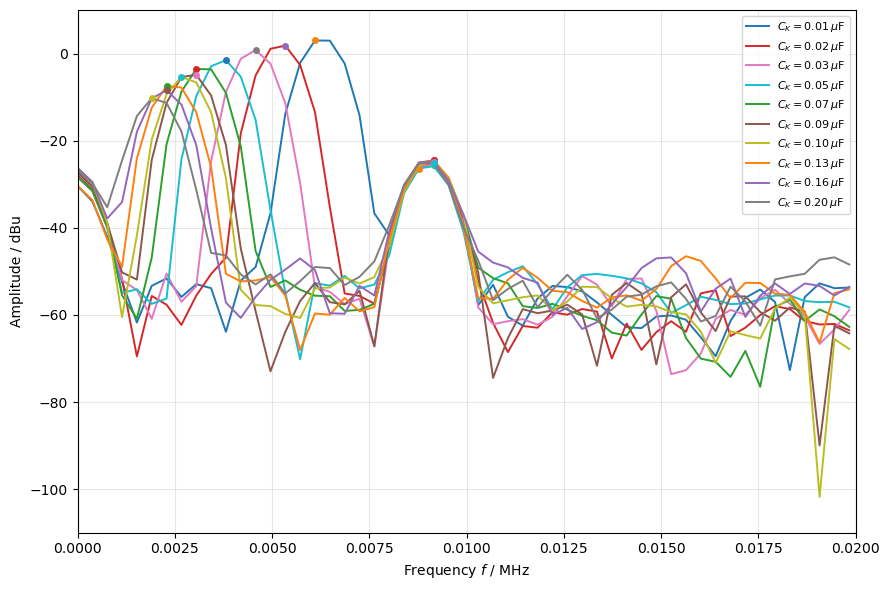


High-point fit result:
C = (0.022000 ± 0.000000) microfarad
C = (22.000 ± 0.000) nF


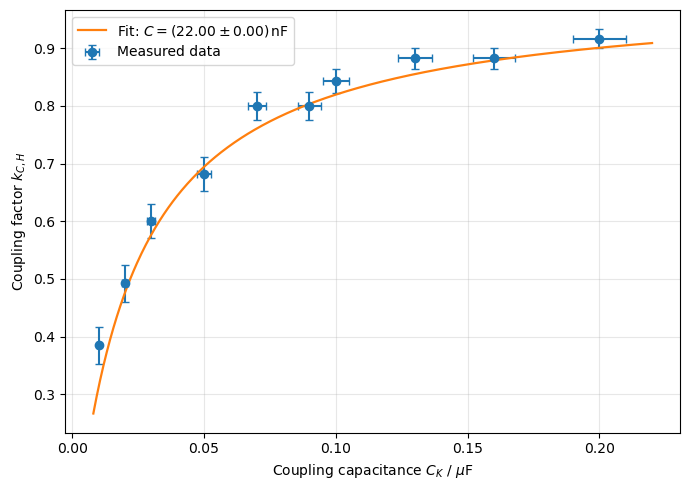

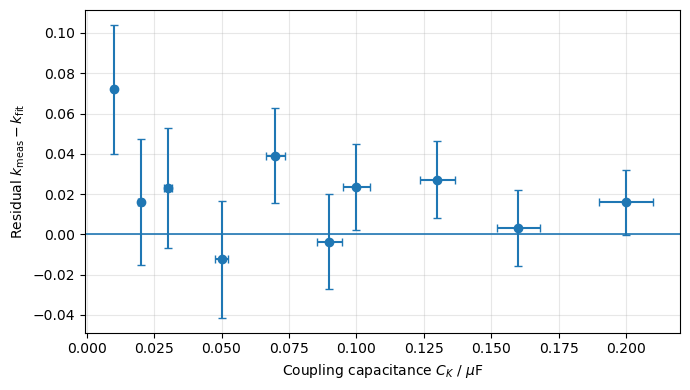


Task 2 summary
--------------
Frequency spacing Δf = 0.00038147 MHz = 0.381470 kHz
Frequency uncertainty u(f) = Δf/2 = 0.00019073 MHz = 0.190735 kHz
Coupling-capacitor uncertainty: u(C_K) = 5% of C_K
Fitted capacitance from high-point circuit:
C = (0.022000 ± 0.000000) microfarad
C = (22.000 ± 0.000) nF

Extracted peak table:


,file,Ck_uF,u_Ck_uF,f_plus_kHz,u_f_plus_kHz,f_minus_kHz,u_f_minus_kHz,k_CH,u_k_CH,k_fit,residual
0,S20.csv,0.01,0.000,6.1035,0.1907,9.1553,0.1907,0.3846,0.0320,0.3125,0.0721
1,S21.csv,0.02,0.001,5.3406,0.1907,9.1553,0.1907,0.4922,0.0313,0.4762,0.0160
2,S22.csv,0.03,0.002,4.5776,0.1907,9.1553,0.1907,0.6000,0.0298,0.5769,0.0231
3,S23.csv,0.05,0.003,3.8147,0.1907,8.7738,0.1907,0.6820,0.0292,0.6944,-0.0124
4,S24.csv,0.07,0.004,3.0518,0.1907,9.1553,0.1907,0.8000,0.0237,0.7609,0.0391
5,S25.csv,0.09,0.004,3.0518,0.1907,9.1553,0.1907,0.8000,0.0237,0.8036,-0.0036
6,S26.csv,0.10,0.005,2.6703,0.1907,9.1553,0.1907,0.8432,0.0215,0.8197,0.0235
7,S27.csv,0.13,0.007,2.2888,0.1907,9.1553,0.1907,0.8824,0.0190,0.8553,0.0271
8,S28.csv,0.16,0.008,2.2888,0.1907,9.1553,0.1907,0.8824,0.0190,0.8791,0.0032
9,S29.csv,0.20,0.010,1.9074,0.1907,9.1553,0.1907,0.9168,0.0163,0.9009,0.0159



Saved files:
task2_outputs\task2_high_point_all_spectra.png
task2_outputs\task2_high_point_peak_check.png
task2_outputs\task2_high_point_coupling_fit.png
task2_outputs\task2_high_point_fit_residuals.png
task2_outputs\task2_high_point_results.csv
task2_outputs\task2_high_point_report_table.csv
task2_outputs\task2_high_point_report_table.tex


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter
from scipy.odr import ODR, Model, RealData
from IPython.display import display

# -----------------------------
# 1. User settings
# -----------------------------

DATA_DIR = "."          # change this if your CSV files are in another folder
OUTPUT_DIR = "task2_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

files = [
    "S20.csv", "S21.csv", "S22.csv", "S23.csv", "S24.csv",
    "S25.csv", "S26.csv", "S27.csv", "S28.csv", "S29.csv"
]

# Coupling capacitor values in microfarad
Ck_uF = np.array([0.01, 0.02, 0.03, 0.05, 0.07, 0.09, 0.10, 0.13, 0.16, 0.20])

# 5% uncertainty in C_K
u_Ck_uF = 0.05 * Ck_uF

# Frequency ranges in MHz
# The spectra are plotted from 0.00 to 0.02 MHz, as requested.
PLOT_REGION_MHZ = (0.00, 0.02)

# Peak extraction is restricted slightly to avoid selecting high-frequency noise peaks.
PEAK_REGION_MHZ = (0.001, 0.012)

# Manual peak override if automatic peak detection selects a wrong peak.
# Format: "filename.csv": (f_plus_MHz, f_minus_MHz)
# Example:
# manual_peaks_MHz = {"S20.csv": (0.00610, 0.00916)}
manual_peaks_MHz = {}

# -----------------------------
# 2. Read PicoScope CSV files
# -----------------------------

def read_picoscope_spectrum(path):
    """
    Reads PicoScope spectrum CSV with:
    Frequency;Channel A
    (MHz);(dBu)
    and decimal commas.
    """
    df = pd.read_csv(path, sep=";", skiprows=[1], decimal=",")
    df.columns = ["frequency_MHz", "amplitude_dBu"]
    df = df.dropna()
    df["frequency_MHz"] = pd.to_numeric(df["frequency_MHz"], errors="coerce")
    df["amplitude_dBu"] = pd.to_numeric(df["amplitude_dBu"], errors="coerce")
    df = df.dropna()
    return df

spectra = {}

for file in files:
    path = os.path.join(DATA_DIR, file)
    spectra[file] = read_picoscope_spectrum(path)

# Frequency spacing and frequency uncertainty
freq_values_MHz = spectra[files[0]]["frequency_MHz"].values
delta_f_MHz = np.mean(np.diff(freq_values_MHz))
u_f_MHz = delta_f_MHz / 2.0

delta_f_kHz = delta_f_MHz * 1000.0
u_f_kHz = u_f_MHz * 1000.0

print(f"Frequency spacing Δf = {delta_f_MHz:.8f} MHz = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_MHz:.8f} MHz = {u_f_kHz:.6f} kHz")

# -----------------------------
# 3. Combined spectrum plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_MHz"] >= PLOT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PLOT_REGION_MHZ[1])
    )

    x_plot = df.loc[mask, "frequency_MHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    label = rf"$C_K={Ck_uF[i]:.2f}\,\mu\mathrm{{F}}$"
    plt.plot(x_plot, y_plot, linewidth=1.4, label=label)

plt.xlabel(r"Frequency $f$ / MHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(0.00, 0.02)
plt.ylim(-110, 10)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_high_point_all_spectra.png"), dpi=300)
plt.show()

# -----------------------------
# 4. Peak extraction
# -----------------------------

def extract_two_main_peaks(df, file):
    """
    Extracts the two dominant peaks in the expected frequency region.
    For the high-point circuit, the lower peak is denoted f_plus and the higher peak f_minus.
    """
    if file in manual_peaks_MHz:
        f_plus, f_minus = manual_peaks_MHz[file]
        return float(f_plus), float(f_minus)

    mask = (
        (df["frequency_MHz"] >= PEAK_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PEAK_REGION_MHZ[1])
    )

    x = df.loc[mask, "frequency_MHz"].values
    y = df.loc[mask, "amplitude_dBu"].values

    # Smooth spectrum to avoid selecting single-bin noise spikes.
    window_length = 9
    if window_length >= len(y):
        window_length = len(y) - 1 if len(y) % 2 == 0 else len(y)
    if window_length < 5:
        window_length = 5
    if window_length % 2 == 0:
        window_length += 1

    y_smooth = savgol_filter(y, window_length=window_length, polyorder=3)

    # Minimum separation between physical peaks.
    min_distance_MHz = 0.001
    min_distance_bins = max(1, int(min_distance_MHz / delta_f_MHz))

    peaks, _ = find_peaks(
        y_smooth,
        prominence=1.0,
        distance=min_distance_bins
    )

    if len(peaks) < 2:
        raise RuntimeError(
            f"Less than two peaks found in {file}. "
            "Adjust PEAK_REGION_MHZ/prominence or use manual_peaks_MHz."
        )

    selected = sorted(peaks, key=lambda idx: y_smooth[idx], reverse=True)[:2]
    selected_freqs = np.sort(x[selected])

    f_plus_MHz = selected_freqs[0]
    f_minus_MHz = selected_freqs[1]

    return f_plus_MHz, f_minus_MHz

peak_rows = []

for i, file in enumerate(files):
    df = spectra[file]
    f_plus_MHz, f_minus_MHz = extract_two_main_peaks(df, file)

    peak_rows.append({
        "file": file,
        "Ck_uF": Ck_uF[i],
        "u_Ck_uF": u_Ck_uF[i],
        "f_plus_MHz": f_plus_MHz,
        "u_f_plus_MHz": u_f_MHz,
        "f_minus_MHz": f_minus_MHz,
        "u_f_minus_MHz": u_f_MHz
    })

task2_df = pd.DataFrame(peak_rows)

# -----------------------------
# 5. Peak-check plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_MHz"] >= PLOT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PLOT_REGION_MHZ[1])
    )

    x_plot = df.loc[mask, "frequency_MHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    plt.plot(
        x_plot,
        y_plot,
        linewidth=1.4,
        label=rf"$C_K={Ck_uF[i]:.2f}\,\mu\mathrm{{F}}$"
    )

    f_plus = task2_df.loc[i, "f_plus_MHz"]
    f_minus = task2_df.loc[i, "f_minus_MHz"]

    y_plus = np.interp(f_plus, x_plot, y_plot)
    y_minus = np.interp(f_minus, x_plot, y_plot)

    plt.plot(f_plus, y_plus, marker="o", markersize=4)
    plt.plot(f_minus, y_minus, marker="o", markersize=4)

plt.xlabel(r"Frequency $f$ / MHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(0.00, 0.02)
plt.ylim(-110, 10)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_high_point_peak_check.png"), dpi=300)
plt.show()

# -----------------------------
# 6. Coupling factor and uncertainty
# -----------------------------

def coupling_factor_high_point(f_plus, f_minus):
    """
    High-point coupling factor:
    k_C,H = (f_minus^2 - f_plus^2)/(f_minus^2 + f_plus^2)
    """
    return (f_minus**2 - f_plus**2) / (f_minus**2 + f_plus**2)

def coupling_factor_uncertainty(f_plus, f_minus, u_f_plus, u_f_minus):
    """
    Gaussian uncertainty propagation for:
    k = (f_minus^2 - f_plus^2)/(f_minus^2 + f_plus^2)

    dk/df_plus  = -4 f_plus f_minus^2 / (f_plus^2 + f_minus^2)^2
    dk/df_minus =  4 f_minus f_plus^2 / (f_plus^2 + f_minus^2)^2
    """
    denominator = (f_plus**2 + f_minus**2)**2

    dk_df_plus = -4.0 * f_plus * f_minus**2 / denominator
    dk_df_minus = 4.0 * f_minus * f_plus**2 / denominator

    return np.sqrt((dk_df_plus * u_f_plus)**2 + (dk_df_minus * u_f_minus)**2)

task2_df["k_CH"] = coupling_factor_high_point(
    task2_df["f_plus_MHz"].values,
    task2_df["f_minus_MHz"].values
)

task2_df["u_k_CH"] = coupling_factor_uncertainty(
    task2_df["f_plus_MHz"].values,
    task2_df["f_minus_MHz"].values,
    task2_df["u_f_plus_MHz"].values,
    task2_df["u_f_minus_MHz"].values
)

# Store frequencies in kHz for table/report readability.
task2_df["f_plus_kHz"] = task2_df["f_plus_MHz"] * 1000.0
task2_df["u_f_plus_kHz"] = task2_df["u_f_plus_MHz"] * 1000.0
task2_df["f_minus_kHz"] = task2_df["f_minus_MHz"] * 1000.0
task2_df["u_f_minus_kHz"] = task2_df["u_f_minus_MHz"] * 1000.0

# -----------------------------
# 7. Fit high-point theoretical model
# -----------------------------
# Model:
# k_C,H(C_K) = C_K / (C + C_K)
# C and C_K are both in microfarad.

def high_point_model_odr(beta, x):
    C_uF = beta[0]
    return x / (C_uF + x)

x = task2_df["Ck_uF"].values
y = task2_df["k_CH"].values
sx = task2_df["u_Ck_uF"].values
sy = task2_df["u_k_CH"].values

model = Model(high_point_model_odr)
data = RealData(x, y, sx=sx, sy=sy)

odr = ODR(data, model, beta0=[0.022])
fit_output = odr.run()

C_fit_uF = fit_output.beta[0]
u_C_fit_uF = fit_output.sd_beta[0]

C_fit_nF = C_fit_uF * 1000.0
u_C_fit_nF = u_C_fit_uF * 1000.0

task2_df["k_fit"] = high_point_model_odr([C_fit_uF], x)
task2_df["residual"] = task2_df["k_CH"] - task2_df["k_fit"]

print("\nHigh-point fit result:")
print(f"C = ({C_fit_uF:.6f} ± {u_C_fit_uF:.6f}) microfarad")
print(f"C = ({C_fit_nF:.3f} ± {u_C_fit_nF:.3f}) nF")

# -----------------------------
# 8. Coupling-factor plot with fit
# -----------------------------

Ck_fit = np.linspace(min(Ck_uF) * 0.8, max(Ck_uF) * 1.1, 500)
k_fit = high_point_model_odr([C_fit_uF], Ck_fit)

plt.figure(figsize=(7, 5))

plt.errorbar(
    task2_df["Ck_uF"],
    task2_df["k_CH"],
    xerr=task2_df["u_Ck_uF"],
    yerr=task2_df["u_k_CH"],
    fmt="o",
    capsize=3,
    label="Measured data"
)

plt.plot(
    Ck_fit,
    k_fit,
    linewidth=1.6,
    label=rf"Fit: $C=({C_fit_nF:.2f}\pm{u_C_fit_nF:.2f})\,\mathrm{{nF}}$"
)

plt.xlabel(r"Coupling capacitance $C_K$ / $\mu\mathrm{F}$")
plt.ylabel(r"Coupling factor $k_{C,H}$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_high_point_coupling_fit.png"), dpi=300)
plt.show()

# -----------------------------
# 9. Residual plot
# -----------------------------

plt.figure(figsize=(7, 4))

plt.errorbar(
    task2_df["Ck_uF"],
    task2_df["residual"],
    xerr=task2_df["u_Ck_uF"],
    yerr=task2_df["u_k_CH"],
    fmt="o",
    capsize=3
)

plt.axhline(0, linewidth=1.2)

plt.xlabel(r"Coupling capacitance $C_K$ / $\mu\mathrm{F}$")
plt.ylabel(r"Residual $k_{\mathrm{meas}}-k_{\mathrm{fit}}$")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_high_point_fit_residuals.png"), dpi=300)
plt.show()

# -----------------------------
# 10. Save result tables
# -----------------------------

task2_df = task2_df[
    [
        "file",
        "Ck_uF", "u_Ck_uF",
        "f_plus_MHz", "u_f_plus_MHz",
        "f_minus_MHz", "u_f_minus_MHz",
        "f_plus_kHz", "u_f_plus_kHz",
        "f_minus_kHz", "u_f_minus_kHz",
        "k_CH", "u_k_CH",
        "k_fit", "residual"
    ]
]

task2_df.to_csv(os.path.join(OUTPUT_DIR, "task2_high_point_results.csv"), index=False)

report_table = task2_df.copy()

report_table["Ck_uF"] = report_table["Ck_uF"].round(3)
report_table["u_Ck_uF"] = report_table["u_Ck_uF"].round(3)
report_table["f_plus_MHz"] = report_table["f_plus_MHz"].round(6)
report_table["u_f_plus_MHz"] = report_table["u_f_plus_MHz"].round(6)
report_table["f_minus_MHz"] = report_table["f_minus_MHz"].round(6)
report_table["u_f_minus_MHz"] = report_table["u_f_minus_MHz"].round(6)
report_table["f_plus_kHz"] = report_table["f_plus_kHz"].round(4)
report_table["u_f_plus_kHz"] = report_table["u_f_plus_kHz"].round(4)
report_table["f_minus_kHz"] = report_table["f_minus_kHz"].round(4)
report_table["u_f_minus_kHz"] = report_table["u_f_minus_kHz"].round(4)
report_table["k_CH"] = report_table["k_CH"].round(4)
report_table["u_k_CH"] = report_table["u_k_CH"].round(4)
report_table["k_fit"] = report_table["k_fit"].round(4)
report_table["residual"] = report_table["residual"].round(4)

report_table = report_table[
    [
        "file",
        "Ck_uF", "u_Ck_uF",
        "f_plus_kHz", "u_f_plus_kHz",
        "f_minus_kHz", "u_f_minus_kHz",
        "k_CH", "u_k_CH",
        "k_fit", "residual"
    ]
]

report_table.to_csv(os.path.join(OUTPUT_DIR, "task2_high_point_report_table.csv"), index=False)

latex_table = report_table.to_latex(
    index=False,
    escape=False,
    column_format="lrrrrrrrrrr"
)

with open(os.path.join(OUTPUT_DIR, "task2_high_point_report_table.tex"), "w") as f:
    f.write(latex_table)

# -----------------------------
# 11. Print summary
# -----------------------------

print("\nTask 2 summary")
print("--------------")
print(f"Frequency spacing Δf = {delta_f_MHz:.8f} MHz = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_MHz:.8f} MHz = {u_f_kHz:.6f} kHz")
print("Coupling-capacitor uncertainty: u(C_K) = 5% of C_K")
print("Fitted capacitance from high-point circuit:")
print(f"C = ({C_fit_uF:.6f} ± {u_C_fit_uF:.6f}) microfarad")
print(f"C = ({C_fit_nF:.3f} ± {u_C_fit_nF:.3f}) nF")

print("\nExtracted peak table:")
display(report_table)

print("\nSaved files:")
for filename in [
    "task2_high_point_all_spectra.png",
    "task2_high_point_peak_check.png",
    "task2_high_point_coupling_fit.png",
    "task2_high_point_fit_residuals.png",
    "task2_high_point_results.csv",
    "task2_high_point_report_table.csv",
    "task2_high_point_report_table.tex"
]:
    print(os.path.join(OUTPUT_DIR, filename))

Frequency spacing Δf = 0.00038147 MHz = 0.381470 kHz
Frequency uncertainty u(f) = Δf/2 = 0.00019073 MHz = 0.190735 kHz
Time spacing Δt = 0.00032000 ms = 0.3200 μs
Time uncertainty u(t) = Δt/2 = 0.00016000 ms = 0.1600 μs
Coupling capacitance C_K = (0.004000 ± 0.000200) μF


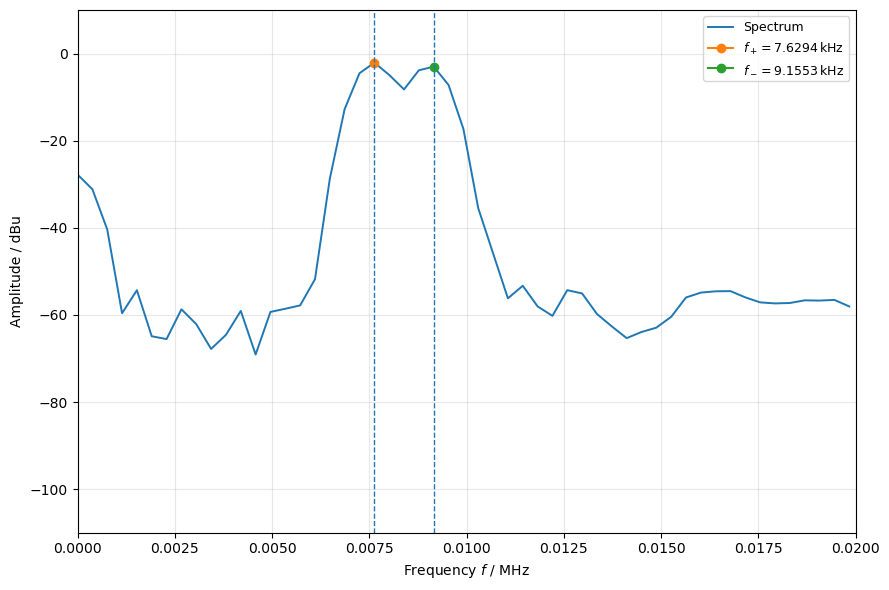

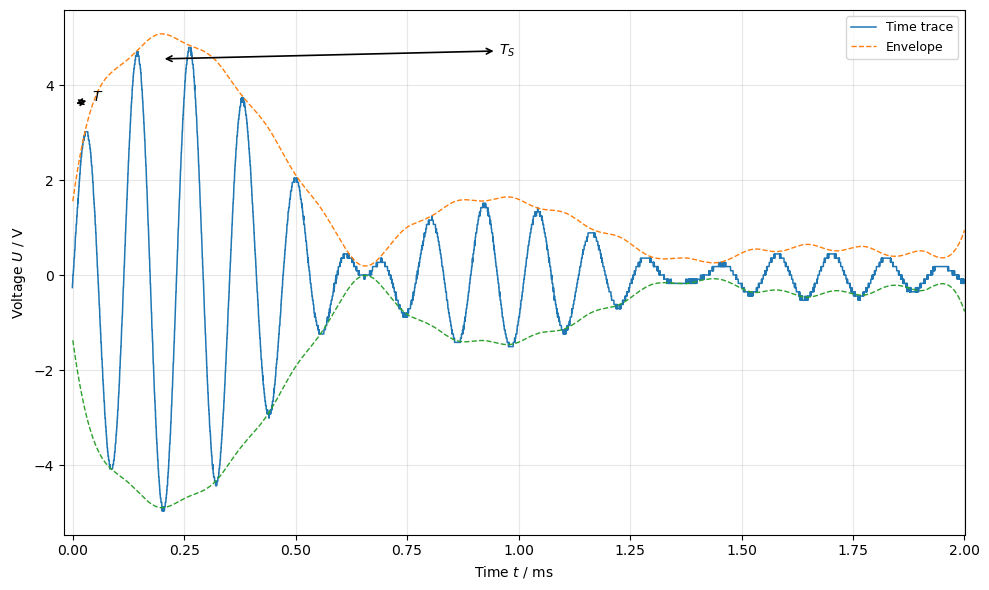

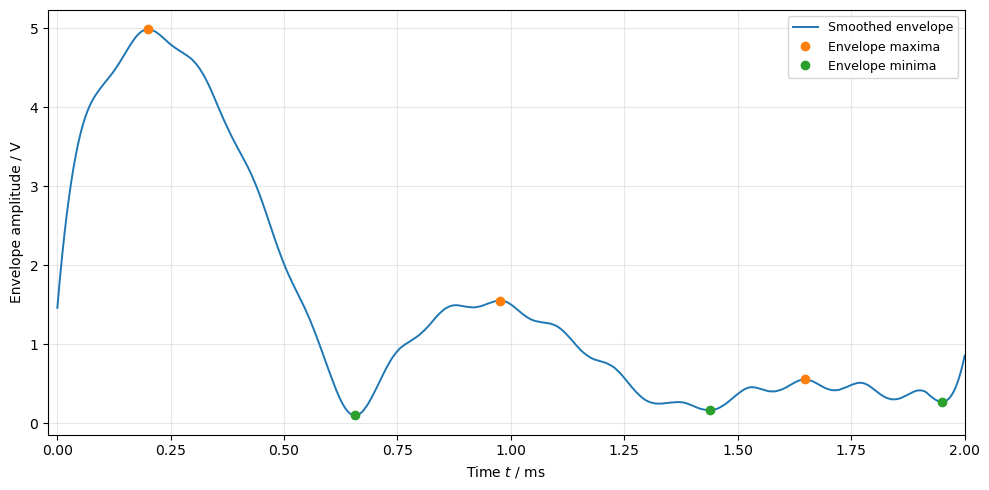


Task 3 frequency-domain results
-------------------------------
C_K = (0.004000 ± 0.000200) μF
f_plus  = (7.6294 ± 0.1907) kHz
f_minus = (9.1553 ± 0.1907) kHz
k_C,H = 0.1803 ± 0.0315

Task 3 period results
---------------------
T_direct  = (0.000640 ± 0.000453) ms
T_calc    = (0.119156 ± 0.001915) ms
T difference = -0.118516 ms
T relative difference = 99.463%
T z-value = 60.232

T_S,direct  = (0.685920 ± 0.063395) ms
T_S,calc    = (0.655360 ± 0.115852) ms
T_S difference = 0.030560 ms
T_S relative difference = 4.663%
T_S z-value = 0.231

Direct time-domain extraction details
-------------------------------------
Number of fast-period estimates from zero crossings: 18
Beat intervals used / ms: [0.77504 0.67392 0.78368 0.51104]
Number of beat intervals used: 4

Spectrum result table:


,quantity,value,unit
0,C_K,0.004,microfarad
1,u(C_K),0.0002,microfarad
2,f_plus,7.62939,kHz
3,u(f_plus),0.190735,kHz
4,f_minus,9.15527,kHz
5,u(f_minus),0.190735,kHz
6,"k_C,H",0.180328,
7,"u(k_C,H)",0.0314845,



Period comparison table:


,quantity,direct_ms,u_direct_ms,calculated_ms,u_calculated_ms,difference_ms,relative_difference_percent,z_value
0,Fast oscillation period T,0.00064,0.00045,0.11916,0.00191,-0.11852,99.46289,60.23200
1,Beat period T_S,0.68592,0.06339,0.65536,0.11585,0.03056,4.66316,0.23141



Saved files:
task3_outputs\task3_spectrum.png
task3_outputs\task3_time_trace.png
task3_outputs\task3_envelope_check.png
task3_outputs\task3_spectrum_results.csv
task3_outputs\task3_period_comparison.csv
task3_outputs\task3_spectrum_results.tex
task3_outputs\task3_period_comparison.tex


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter, hilbert
from IPython.display import display

# -----------------------------
# 1. User settings
# -----------------------------

DATA_DIR = "."          # change this if your CSV files are in another folder
OUTPUT_DIR = "task3_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

spectrum_file = "S3.csv"
time_file = "T3.csv"

Ck_uF = 0.004
u_Ck_uF = 0.05 * Ck_uF

# Frequency plot range in MHz
SPECTRUM_PLOT_REGION_MHZ = (0.00, 0.02)
SPECTRUM_YLIM_DBU = (-110, 10)

# Peak extraction range in MHz
PEAK_REGION_MHZ = (0.001, 0.012)

# Time plot range in ms
TIME_PLOT_REGION_MS = (-0.02, 2.00)

# Manual overrides, only use if automatic detection selects wrong values.
# Example:
# manual_spectrum_peaks_MHz = (0.007629, 0.009155)
manual_spectrum_peaks_MHz = None

# Direct time measurement override.
# Format: (t_start_ms, t_end_ms, number_of_periods_between_markers)
# Example:
# manual_T_markers_ms = (0.05, 0.65, 5)
# manual_TS_markers_ms = (0.20, 0.95, 1)
manual_T_markers_ms = None
manual_TS_markers_ms = None

# -----------------------------
# 2. Read CSV files
# -----------------------------

def read_picoscope_spectrum(path):
    """
    Reads PicoScope spectrum CSV with:
    Frequency;Channel A
    (MHz);(dBu)
    and decimal commas.
    """
    df = pd.read_csv(path, sep=";", skiprows=[1], decimal=",")
    df.columns = ["frequency_MHz", "amplitude_dBu"]
    df = df.dropna()
    df["frequency_MHz"] = pd.to_numeric(df["frequency_MHz"], errors="coerce")
    df["amplitude_dBu"] = pd.to_numeric(df["amplitude_dBu"], errors="coerce")
    df = df.dropna()
    return df

def read_picoscope_time_trace(path):
    """
    Reads PicoScope time trace CSV with:
    Time;Channel A
    (ms);(V)
    and decimal commas.
    """
    df = pd.read_csv(path, sep=";", skiprows=[1], decimal=",")
    df.columns = ["time_ms", "voltage_V"]
    df = df.dropna()
    df["time_ms"] = pd.to_numeric(df["time_ms"], errors="coerce")
    df["voltage_V"] = pd.to_numeric(df["voltage_V"], errors="coerce")
    df = df.dropna()
    return df

spectrum_df = read_picoscope_spectrum(os.path.join(DATA_DIR, spectrum_file))
time_df = read_picoscope_time_trace(os.path.join(DATA_DIR, time_file))

# Frequency spacing and uncertainty
freq_values_MHz = spectrum_df["frequency_MHz"].values
delta_f_MHz = np.mean(np.diff(freq_values_MHz))
u_f_MHz = delta_f_MHz / 2.0

delta_f_kHz = delta_f_MHz * 1000.0
u_f_kHz = u_f_MHz * 1000.0

# Time spacing and uncertainty
time_values_ms = time_df["time_ms"].values
delta_t_ms = np.mean(np.diff(time_values_ms))
u_t_ms = delta_t_ms / 2.0

print(f"Frequency spacing Δf = {delta_f_MHz:.8f} MHz = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_MHz:.8f} MHz = {u_f_kHz:.6f} kHz")
print(f"Time spacing Δt = {delta_t_ms:.8f} ms = {delta_t_ms*1000:.4f} μs")
print(f"Time uncertainty u(t) = Δt/2 = {u_t_ms:.8f} ms = {u_t_ms*1000:.4f} μs")
print(f"Coupling capacitance C_K = ({Ck_uF:.6f} ± {u_Ck_uF:.6f}) μF")

# -----------------------------
# 3. Extract spectral peak frequencies
# -----------------------------

def extract_two_spectrum_peaks(df):
    """
    Extracts the two main resonance peaks from the spectrum.
    The lower-frequency peak is called f_plus and the higher-frequency peak f_minus.
    """
    if manual_spectrum_peaks_MHz is not None:
        f1, f2 = manual_spectrum_peaks_MHz
        f_sorted = np.sort([f1, f2])
        return float(f_sorted[0]), float(f_sorted[1])

    mask = (
        (df["frequency_MHz"] >= PEAK_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PEAK_REGION_MHZ[1])
    )

    x = df.loc[mask, "frequency_MHz"].values
    y = df.loc[mask, "amplitude_dBu"].values

    # Raw peak finding is used because the two beat peaks can be close and smoothing can merge them.
    min_distance_MHz = 0.001
    min_distance_bins = max(1, int(min_distance_MHz / delta_f_MHz))

    peaks, properties = find_peaks(
        y,
        prominence=1.0,
        distance=min_distance_bins
    )

    if len(peaks) < 2:
        raise RuntimeError(
            "Less than two peaks were found in the spectrum. "
            "Adjust PEAK_REGION_MHZ or set manual_spectrum_peaks_MHz."
        )

    selected = sorted(peaks, key=lambda idx: y[idx], reverse=True)[:2]
    selected_freqs = np.sort(x[selected])

    f_plus_MHz = selected_freqs[0]
    f_minus_MHz = selected_freqs[1]

    return f_plus_MHz, f_minus_MHz

f_plus_MHz, f_minus_MHz = extract_two_spectrum_peaks(spectrum_df)

f_plus_kHz = f_plus_MHz * 1000.0
f_minus_kHz = f_minus_MHz * 1000.0

# -----------------------------
# 4. Frequency-domain calculations
# -----------------------------

def coupling_factor(f_plus, f_minus):
    return (f_minus**2 - f_plus**2) / (f_minus**2 + f_plus**2)

def coupling_factor_uncertainty(f_plus, f_minus, u_f_plus, u_f_minus):
    denominator = (f_plus**2 + f_minus**2)**2
    dk_df_plus = -4.0 * f_plus * f_minus**2 / denominator
    dk_df_minus = 4.0 * f_minus * f_plus**2 / denominator

    return np.sqrt((dk_df_plus * u_f_plus)**2 + (dk_df_minus * u_f_minus)**2)

k_CH = coupling_factor(f_plus_kHz, f_minus_kHz)
u_k_CH = coupling_factor_uncertainty(f_plus_kHz, f_minus_kHz, u_f_kHz, u_f_kHz)

# Periods in ms because 1/kHz = ms.
T_calc_ms = 2.0 / (f_plus_kHz + f_minus_kHz)
TS_calc_ms = 1.0 / abs(f_minus_kHz - f_plus_kHz)

u_T_calc_ms = (
    2.0 * np.sqrt(u_f_kHz**2 + u_f_kHz**2)
    / (f_plus_kHz + f_minus_kHz)**2
)

u_TS_calc_ms = (
    np.sqrt(u_f_kHz**2 + u_f_kHz**2)
    / (f_minus_kHz - f_plus_kHz)**2
)

# -----------------------------
# 5. Direct time-domain calculations
# -----------------------------

# Use only t >= 0 for direct period analysis
time_positive_df = time_df[time_df["time_ms"] >= 0].copy()

t_ms = time_positive_df["time_ms"].values
v_raw = time_positive_df["voltage_V"].values

# Estimate baseline from the final 10% of the time trace
n_tail = max(10, int(0.10 * len(v_raw)))
baseline = np.median(v_raw[-n_tail:])
v = v_raw - baseline

# Envelope from Hilbert transform
analytic_signal = hilbert(v)
envelope = np.abs(analytic_signal)

# Smooth envelope
dt_ms = np.mean(np.diff(t_ms))
window_ms = 0.16
window_length = int(window_ms / dt_ms)

if window_length < 5:
    window_length = 5
if window_length % 2 == 0:
    window_length += 1
if window_length >= len(envelope):
    window_length = len(envelope) - 1
    if window_length % 2 == 0:
        window_length -= 1

envelope_smooth = savgol_filter(envelope, window_length=window_length, polyorder=3)

# -----------------------------
# 5a. Direct fast oscillation period T
# -----------------------------

def interpolated_zero_crossings(t, y, env, threshold):
    """
    Finds interpolated zero crossings where the envelope is above a threshold.
    """
    zc = []

    for i in range(len(y) - 1):
        if y[i] == 0:
            t_cross = t[i]
        elif y[i] * y[i + 1] < 0:
            t_cross = t[i] - y[i] * (t[i + 1] - t[i]) / (y[i + 1] - y[i])
        else:
            continue

        local_env = 0.5 * (env[i] + env[i + 1])
        if local_env >= threshold:
            zc.append(t_cross)

    return np.array(zc)

if manual_T_markers_ms is not None:
    t1_T, t2_T, N_T = manual_T_markers_ms
    T_direct_ms = (t2_T - t1_T) / N_T
    u_T_direct_ms = np.sqrt(2) * u_t_ms / N_T
    T_marker_start_ms = t1_T
    T_marker_end_ms = t2_T
    N_fast_period_estimates = 1
else:
    envelope_threshold = 0.25 * np.max(envelope_smooth)
    zero_crossings_ms = interpolated_zero_crossings(t_ms, v, envelope_smooth, envelope_threshold)

    if len(zero_crossings_ms) < 4:
        raise RuntimeError(
            "Too few zero crossings found for direct period measurement. "
            "Set manual_T_markers_ms."
        )

    half_periods_ms = np.diff(zero_crossings_ms)

    # Remove outliers, for example crossings near the envelope minimum or noise at late times.
    median_half_period = np.median(half_periods_ms)
    inlier_mask = (
        (half_periods_ms > 0.5 * median_half_period) &
        (half_periods_ms < 1.5 * median_half_period)
    )

    half_periods_inlier_ms = half_periods_ms[inlier_mask]
    T_values_ms = 2.0 * half_periods_inlier_ms

    T_direct_ms = np.median(T_values_ms)

    if len(T_values_ms) > 1:
        u_T_stat_ms = np.std(T_values_ms, ddof=1) / np.sqrt(len(T_values_ms))
    else:
        u_T_stat_ms = 0.0

    # Resolution contribution for a full period from two zero-crossing times
    u_T_res_ms = 2.0 * np.sqrt(2.0) * u_t_ms
    u_T_direct_ms = np.sqrt(u_T_stat_ms**2 + u_T_res_ms**2)

    # For plotting: use the first two zero crossings separated by approximately one full period
    if len(zero_crossings_ms) >= 3:
        T_marker_start_ms = zero_crossings_ms[0]
        T_marker_end_ms = zero_crossings_ms[2]
    else:
        T_marker_start_ms = np.nan
        T_marker_end_ms = np.nan

    N_fast_period_estimates = len(T_values_ms)

# -----------------------------
# 5b. Direct beat period T_S
# -----------------------------

def direct_beat_period_from_envelope(t, env_smooth):
    """
    Estimates beat period from adjacent envelope maxima and minima.
    Returns mean interval and uncertainty estimate.
    """
    min_distance_ms = 0.35
    min_distance_bins = max(1, int(min_distance_ms / dt_ms))

    prominence = 0.03 * np.max(env_smooth)

    envelope_maxima, _ = find_peaks(
        env_smooth,
        prominence=prominence,
        distance=min_distance_bins
    )

    envelope_minima, _ = find_peaks(
        -env_smooth,
        prominence=prominence,
        distance=min_distance_bins
    )

    intervals = []

    if len(envelope_maxima) >= 2:
        max_intervals = np.diff(t[envelope_maxima])
        intervals.extend(max_intervals.tolist())

    if len(envelope_minima) >= 2:
        min_intervals = np.diff(t[envelope_minima])
        intervals.extend(min_intervals.tolist())

    intervals = np.array(intervals)

    if len(intervals) == 0:
        return np.nan, np.nan, envelope_maxima, envelope_minima, intervals

    TS_direct = np.mean(intervals)

    if len(intervals) > 1:
        u_TS_stat = np.std(intervals, ddof=1) / np.sqrt(len(intervals))
    else:
        u_TS_stat = 0.0

    # Resolution contribution from two time markers
    u_TS_res = np.sqrt(2.0) * u_t_ms
    u_TS_direct = np.sqrt(u_TS_stat**2 + u_TS_res**2)

    return TS_direct, u_TS_direct, envelope_maxima, envelope_minima, intervals

if manual_TS_markers_ms is not None:
    t1_TS, t2_TS, N_TS = manual_TS_markers_ms
    TS_direct_ms = (t2_TS - t1_TS) / N_TS
    u_TS_direct_ms = np.sqrt(2.0) * u_t_ms / N_TS
    envelope_maxima = np.array([])
    envelope_minima = np.array([])
    beat_intervals_ms = np.array([TS_direct_ms])
    TS_marker_start_ms = t1_TS
    TS_marker_end_ms = t2_TS
else:
    TS_direct_ms, u_TS_direct_ms, envelope_maxima, envelope_minima, beat_intervals_ms = (
        direct_beat_period_from_envelope(t_ms, envelope_smooth)
    )

    if np.isnan(TS_direct_ms):
        raise RuntimeError(
            "Could not determine beat period from the envelope. "
            "Set manual_TS_markers_ms."
        )

    # For plotting: prefer first two envelope maxima, otherwise first two minima
    if len(envelope_maxima) >= 2:
        TS_marker_start_ms = t_ms[envelope_maxima[0]]
        TS_marker_end_ms = t_ms[envelope_maxima[1]]
    elif len(envelope_minima) >= 2:
        TS_marker_start_ms = t_ms[envelope_minima[0]]
        TS_marker_end_ms = t_ms[envelope_minima[1]]
    else:
        TS_marker_start_ms = np.nan
        TS_marker_end_ms = np.nan

N_beat_intervals = len(beat_intervals_ms)

# -----------------------------
# 6. Comparison calculations
# -----------------------------

difference_T_ms = T_direct_ms - T_calc_ms
u_difference_T_ms = np.sqrt(u_T_direct_ms**2 + u_T_calc_ms**2)
z_T = abs(difference_T_ms) / u_difference_T_ms

difference_TS_ms = TS_direct_ms - TS_calc_ms
u_difference_TS_ms = np.sqrt(u_TS_direct_ms**2 + u_TS_calc_ms**2)
z_TS = abs(difference_TS_ms) / u_difference_TS_ms

relative_difference_T_percent = 100.0 * abs(difference_T_ms) / T_calc_ms
relative_difference_TS_percent = 100.0 * abs(difference_TS_ms) / TS_calc_ms

# -----------------------------
# 7. Spectrum plot with peaks
# -----------------------------

plt.figure(figsize=(9, 6))

mask_plot = (
    (spectrum_df["frequency_MHz"] >= SPECTRUM_PLOT_REGION_MHZ[0]) &
    (spectrum_df["frequency_MHz"] <= SPECTRUM_PLOT_REGION_MHZ[1])
)

x_spec = spectrum_df.loc[mask_plot, "frequency_MHz"].values
y_spec = spectrum_df.loc[mask_plot, "amplitude_dBu"].values

plt.plot(x_spec, y_spec, linewidth=1.4, label="Spectrum")

y_f_plus = np.interp(f_plus_MHz, x_spec, y_spec)
y_f_minus = np.interp(f_minus_MHz, x_spec, y_spec)

plt.plot(f_plus_MHz, y_f_plus, marker="o", markersize=6, label=rf"$f_+={f_plus_kHz:.4f}\,\mathrm{{kHz}}$")
plt.plot(f_minus_MHz, y_f_minus, marker="o", markersize=6, label=rf"$f_-={f_minus_kHz:.4f}\,\mathrm{{kHz}}$")

plt.axvline(f_plus_MHz, linewidth=1.0, linestyle="--")
plt.axvline(f_minus_MHz, linewidth=1.0, linestyle="--")

plt.xlabel(r"Frequency $f$ / MHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(SPECTRUM_PLOT_REGION_MHZ)
plt.ylim(SPECTRUM_YLIM_DBU)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_spectrum.png"), dpi=300)
plt.show()

# -----------------------------
# 8. Time trace plot with envelope and period markers
# -----------------------------

plt.figure(figsize=(10, 6))

mask_time_plot = (
    (time_df["time_ms"] >= TIME_PLOT_REGION_MS[0]) &
    (time_df["time_ms"] <= TIME_PLOT_REGION_MS[1])
)

x_time = time_df.loc[mask_time_plot, "time_ms"].values
y_time = time_df.loc[mask_time_plot, "voltage_V"].values

plt.plot(x_time, y_time, linewidth=1.1, label="Time trace")

# Plot envelope on baseline-corrected scale, shifted back by the baseline for visual comparison
plt.plot(t_ms, envelope_smooth + baseline, linestyle="--", linewidth=1.0, label="Envelope")
plt.plot(t_ms, -envelope_smooth + baseline, linestyle="--", linewidth=1.0)

# Mark fast period T
if not np.isnan(T_marker_start_ms) and not np.isnan(T_marker_end_ms):
    y_annot_T = np.nanmax(y_time) * 0.75
    plt.annotate(
        r"$T$",
        xy=(T_marker_start_ms, y_annot_T),
        xytext=(T_marker_end_ms, y_annot_T),
        arrowprops=dict(arrowstyle="<->", lw=1.2),
        ha="center",
        va="bottom"
    )

# Mark beat period T_S
if not np.isnan(TS_marker_start_ms) and not np.isnan(TS_marker_end_ms):
    y_annot_TS = np.nanmax(y_time) * 0.95
    plt.annotate(
        r"$T_S$",
        xy=(TS_marker_start_ms, y_annot_TS),
        xytext=(TS_marker_end_ms, y_annot_TS),
        arrowprops=dict(arrowstyle="<->", lw=1.2),
        ha="center",
        va="bottom"
    )

plt.xlabel(r"Time $t$ / ms")
plt.ylabel(r"Voltage $U$ / V")
plt.xlim(TIME_PLOT_REGION_MS)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_time_trace.png"), dpi=300)
plt.show()

# -----------------------------
# 9. Optional envelope-check plot
# -----------------------------

plt.figure(figsize=(10, 5))

plt.plot(t_ms, envelope_smooth, linewidth=1.4, label="Smoothed envelope")

if len(envelope_maxima) > 0:
    plt.plot(t_ms[envelope_maxima], envelope_smooth[envelope_maxima], marker="o", linestyle="None", label="Envelope maxima")

if len(envelope_minima) > 0:
    plt.plot(t_ms[envelope_minima], envelope_smooth[envelope_minima], marker="o", linestyle="None", label="Envelope minima")

plt.xlabel(r"Time $t$ / ms")
plt.ylabel(r"Envelope amplitude / V")
plt.xlim(TIME_PLOT_REGION_MS)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_envelope_check.png"), dpi=300)
plt.show()

# -----------------------------
# 10. Save result tables
# -----------------------------

spectrum_result_table = pd.DataFrame({
    "quantity": [
        "C_K",
        "u(C_K)",
        "f_plus",
        "u(f_plus)",
        "f_minus",
        "u(f_minus)",
        "k_C,H",
        "u(k_C,H)"
    ],
    "value": [
        Ck_uF,
        u_Ck_uF,
        f_plus_kHz,
        u_f_kHz,
        f_minus_kHz,
        u_f_kHz,
        k_CH,
        u_k_CH
    ],
    "unit": [
        "microfarad",
        "microfarad",
        "kHz",
        "kHz",
        "kHz",
        "kHz",
        "",
        ""
    ]
})

comparison_table = pd.DataFrame({
    "quantity": [
        "Fast oscillation period T",
        "Beat period T_S"
    ],
    "direct_ms": [
        T_direct_ms,
        TS_direct_ms
    ],
    "u_direct_ms": [
        u_T_direct_ms,
        u_TS_direct_ms
    ],
    "calculated_ms": [
        T_calc_ms,
        TS_calc_ms
    ],
    "u_calculated_ms": [
        u_T_calc_ms,
        u_TS_calc_ms
    ],
    "difference_ms": [
        difference_T_ms,
        difference_TS_ms
    ],
    "relative_difference_percent": [
        relative_difference_T_percent,
        relative_difference_TS_percent
    ],
    "z_value": [
        z_T,
        z_TS
    ]
})

# Rounded report tables
spectrum_report_table = spectrum_result_table.copy()
spectrum_report_table["value"] = spectrum_report_table["value"].map(lambda x: f"{x:.6g}")

comparison_report_table = comparison_table.copy()
for col in [
    "direct_ms",
    "u_direct_ms",
    "calculated_ms",
    "u_calculated_ms",
    "difference_ms",
    "relative_difference_percent",
    "z_value"
]:
    comparison_report_table[col] = comparison_report_table[col].round(5)

# Save CSV
spectrum_result_table.to_csv(os.path.join(OUTPUT_DIR, "task3_spectrum_results.csv"), index=False)
comparison_table.to_csv(os.path.join(OUTPUT_DIR, "task3_period_comparison.csv"), index=False)

# Save LaTeX
with open(os.path.join(OUTPUT_DIR, "task3_spectrum_results.tex"), "w") as f:
    f.write(spectrum_report_table.to_latex(index=False, escape=False))

with open(os.path.join(OUTPUT_DIR, "task3_period_comparison.tex"), "w") as f:
    f.write(comparison_report_table.to_latex(index=False, escape=False))

# -----------------------------
# 11. Print summary
# -----------------------------

print("\nTask 3 frequency-domain results")
print("-------------------------------")
print(f"C_K = ({Ck_uF:.6f} ± {u_Ck_uF:.6f}) μF")
print(f"f_plus  = ({f_plus_kHz:.4f} ± {u_f_kHz:.4f}) kHz")
print(f"f_minus = ({f_minus_kHz:.4f} ± {u_f_kHz:.4f}) kHz")
print(f"k_C,H = {k_CH:.4f} ± {u_k_CH:.4f}")

print("\nTask 3 period results")
print("---------------------")
print(f"T_direct  = ({T_direct_ms:.6f} ± {u_T_direct_ms:.6f}) ms")
print(f"T_calc    = ({T_calc_ms:.6f} ± {u_T_calc_ms:.6f}) ms")
print(f"T difference = {difference_T_ms:.6f} ms")
print(f"T relative difference = {relative_difference_T_percent:.3f}%")
print(f"T z-value = {z_T:.3f}")

print()
print(f"T_S,direct  = ({TS_direct_ms:.6f} ± {u_TS_direct_ms:.6f}) ms")
print(f"T_S,calc    = ({TS_calc_ms:.6f} ± {u_TS_calc_ms:.6f}) ms")
print(f"T_S difference = {difference_TS_ms:.6f} ms")
print(f"T_S relative difference = {relative_difference_TS_percent:.3f}%")
print(f"T_S z-value = {z_TS:.3f}")

print("\nDirect time-domain extraction details")
print("-------------------------------------")
print(f"Number of fast-period estimates from zero crossings: {N_fast_period_estimates}")
print(f"Beat intervals used / ms: {np.round(beat_intervals_ms, 6)}")
print(f"Number of beat intervals used: {N_beat_intervals}")

print("\nSpectrum result table:")
display(spectrum_report_table)

print("\nPeriod comparison table:")
display(comparison_report_table)

print("\nSaved files:")
for filename in [
    "task3_spectrum.png",
    "task3_time_trace.png",
    "task3_envelope_check.png",
    "task3_spectrum_results.csv",
    "task3_period_comparison.csv",
    "task3_spectrum_results.tex",
    "task3_period_comparison.tex"
]:
    print(os.path.join(OUTPUT_DIR, filename))

Frequency spacing Δf = 0.00038147 MHz = 0.381470 kHz
Frequency uncertainty u(f) = Δf/2 = 0.00019073 MHz = 0.190735 kHz
Distance uncertainty u(d) = 0.100 cm
Capacitance C = (22.000 ± 0.000) nF


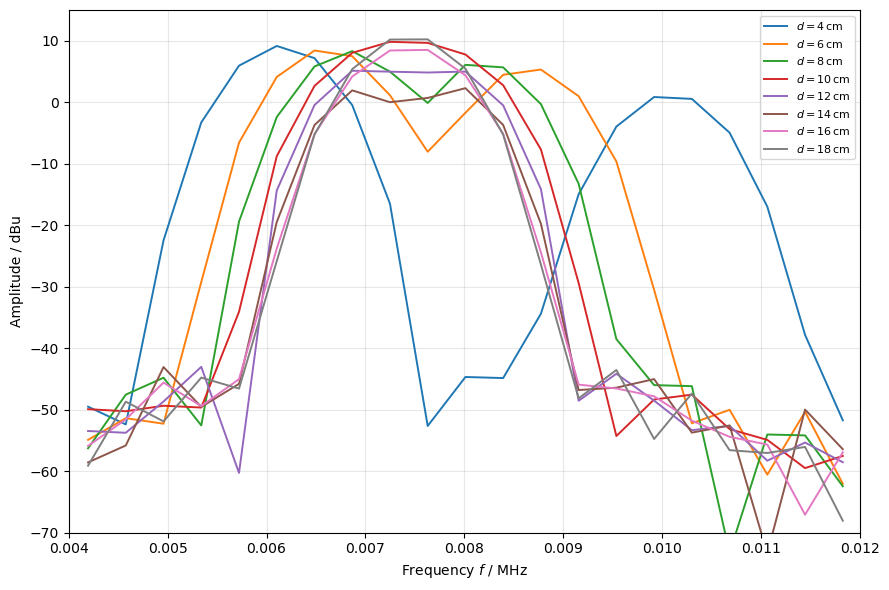

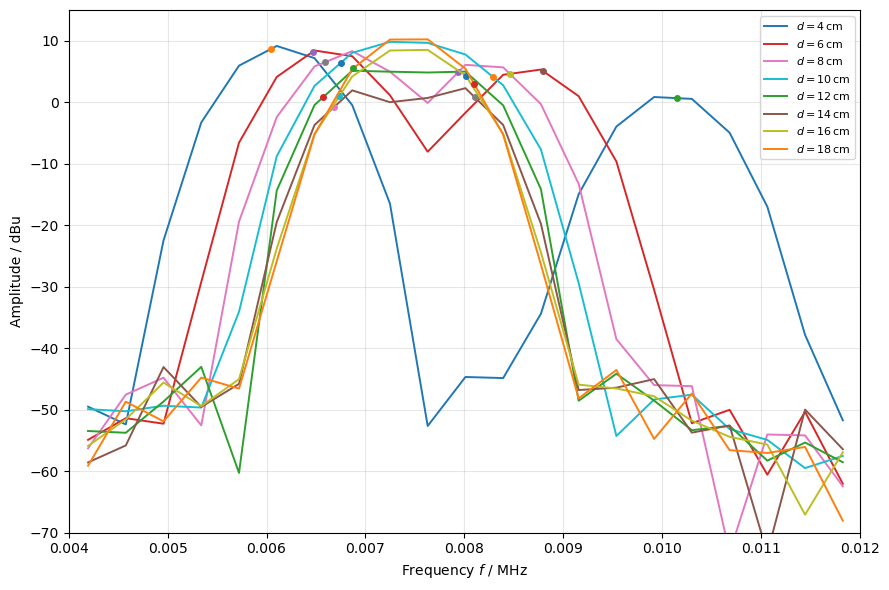

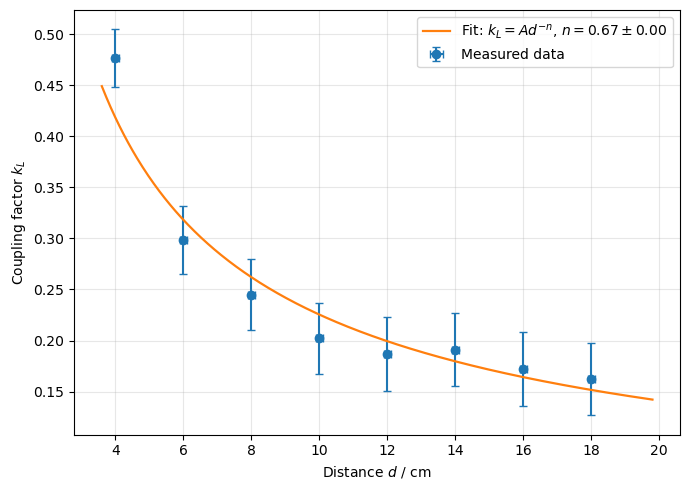

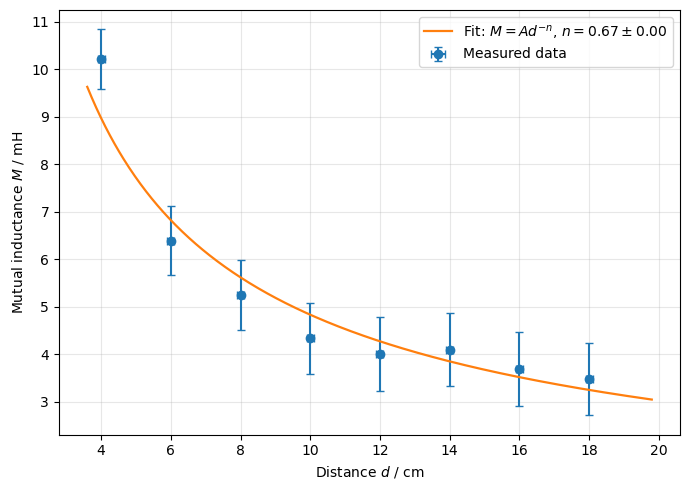

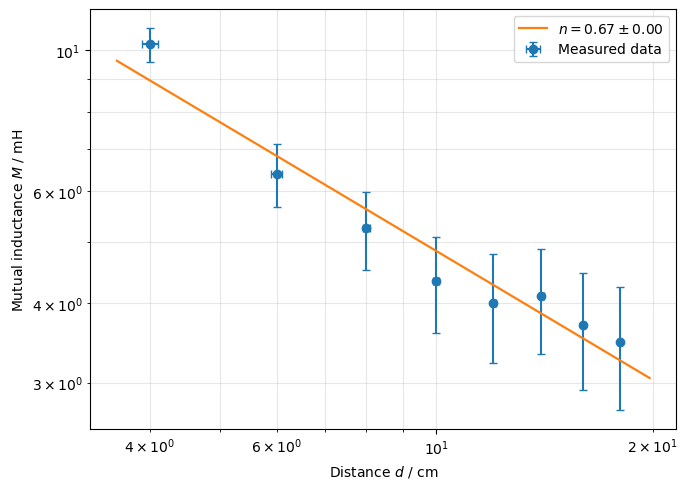

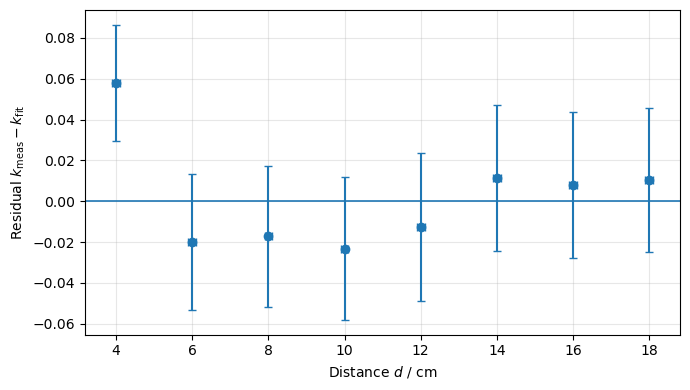

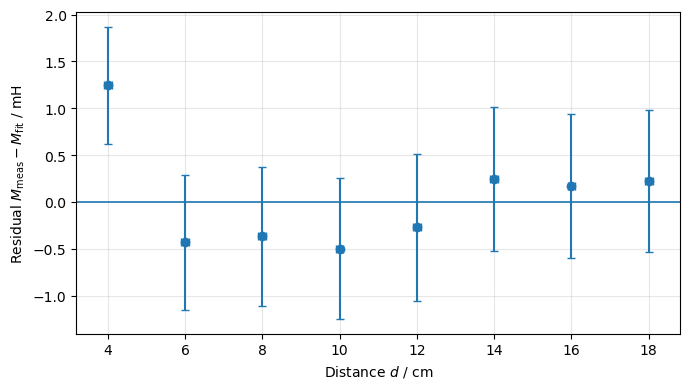


Task 4 summary
--------------
Frequency spacing Δf = 0.00038147 MHz = 0.381470 kHz
Frequency uncertainty u(f) = 0.00019073 MHz = 0.190735 kHz
Distance uncertainty u(d) = 0.100 cm
C = (22.000 ± 0.000) nF

Because no uncoupled f0 was measured, f0 was estimated from each pair of split frequencies:
f0_est = (7.3266 ± 0.0518) kHz
L = (21.4493 ± 0.3034) mH

Power-law fits:
k_L(d) = A d^(-n): n = 0.6746 ± 0.0000
M(d)   = A d^(-n): n = 0.6746 ± 0.0000

Fit summary table:


,quantity,value,unit
0,C,22,nF
1,u(C),0,nF
2,f0_est,7.32659,kHz
3,u(f0_est),0.0518095,kHz
4,L,21.4493,mH
5,u(L),0.303355,mH
6,n from k_L(d),0.674554,
7,u(n from k_L(d)),0,
8,n from M(d),0.674554,
9,u(n from M(d)),0,



Task 4 result table:


,file,d_cm,u_d_cm,f_plus_kHz,u_f_plus_kHz,f_minus_kHz,u_f_minus_kHz,k_L,u_k_L,f0_est_kHz,u_f0_est_kHz,L_mH,u_L_mH,M_mH,u_M_mH,k_fit,k_residual,M_fit_mH,M_residual_mH
0,S41.csv,4.0,0.1,6.0465,0.1907,10.1519,0.1907,0.4763,0.0284,7.3466,0.1743,21.4493,0.3034,10.2164,0.6258,0.4182,0.0581,8.9702,1.2462
1,S42.csv,6.0,0.1,6.4677,0.1907,8.7949,0.1907,0.2980,0.0334,7.3687,0.1513,21.4493,0.3034,6.3924,0.7211,0.3181,-0.0201,6.8237,-0.4313
2,S43.csv,8.0,0.1,6.5922,0.1907,8.4643,0.1907,0.2449,0.0345,7.3553,0.1466,21.4493,0.3034,5.2526,0.7432,0.2620,-0.0171,5.6201,-0.3675
3,S44.csv,10.0,0.1,6.7513,0.1907,8.2876,0.1907,0.2022,0.0349,7.4024,0.1434,21.4493,0.3034,4.3373,0.7521,0.2254,-0.0232,4.8347,-0.4974
4,S45.csv,12.0,0.1,6.5719,0.1907,7.9385,0.1907,0.1867,0.0364,7.1591,0.1415,21.4493,0.3034,4.0048,0.7820,0.1993,-0.0126,4.2752,-0.2704
5,S46.csv,14.0,0.1,6.6783,0.1907,8.1042,0.1907,0.1911,0.0357,7.2887,0.1420,21.4493,0.3034,4.0996,0.7670,0.1796,0.0115,3.8530,0.2466
6,S47.csv,16.0,0.1,6.7362,0.1907,8.0158,0.1907,0.1722,0.0359,7.2931,0.1412,21.4493,0.3034,3.6933,0.7716,0.1642,0.0080,3.5211,0.1722
7,S48.csv,18.0,0.1,6.8762,0.1907,8.0981,0.1907,0.1621,0.0354,7.4126,0.1399,21.4493,0.3034,3.4774,0.7616,0.1516,0.0105,3.2522,0.2252



Saved files:
task4_outputs\task4_inductive_all_spectra.png
task4_outputs\task4_inductive_peak_check.png
task4_outputs\task4_k_vs_distance.png
task4_outputs\task4_M_vs_distance.png
task4_outputs\task4_M_loglog_power_law.png
task4_outputs\task4_k_fit_residuals.png
task4_outputs\task4_M_fit_residuals.png
task4_outputs\task4_inductive_results.csv
task4_outputs\task4_inductive_report_table.csv
task4_outputs\task4_inductive_report_table.tex
task4_outputs\task4_fit_summary.csv
task4_outputs\task4_fit_summary.tex


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter
from scipy.optimize import curve_fit
from scipy.odr import ODR, Model, RealData
from IPython.display import display

# -----------------------------
# 1. User settings
# -----------------------------

DATA_DIR = "."          # change this if your CSV files are in another folder
OUTPUT_DIR = "task4_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

files = [
    "S41.csv", "S42.csv", "S43.csv", "S44.csv",
    "S45.csv", "S46.csv", "S47.csv", "S48.csv"
]

# Distances in cm
d_cm = np.array([4, 6, 8, 10, 12, 14, 16, 18], dtype=float)
u_d_cm = np.full_like(d_cm, 0.1, dtype=float)

# Capacitance used for inductance calculation
C_nF = 22.0
u_C_nF = 0.0     # no uncertainty was supplied for C; change this if you want to include one

C_F = C_nF * 1e-9
u_C_F = u_C_nF * 1e-9

# Frequency ranges in MHz
PLOT_REGION_MHZ = (0.004, 0.012)
PEAK_FIT_REGION_MHZ = (0.0045, 0.0115)

# Plot y-axis range
SPECTRUM_YLIM_DBU = (-70, 15)

# Peak extraction method:
# "double_gaussian" fits two broad peaks in the main resonance region.
# If any peak choice looks wrong in the peak-check plot, manually override below.
PEAK_METHOD = "double_gaussian"

# Manual peak override if needed.
# Format: "filename.csv": (f_plus_MHz, f_minus_MHz)
# Example:
# manual_peaks_MHz = {"S41.csv": (0.006104, 0.009918)}
manual_peaks_MHz = {}

# Optional initial guesses for double-Gaussian peak fit, in MHz.
# These are only starting values; the fit determines the final peak positions.
initial_peak_guesses_MHz = {
    "S41.csv": (0.0061, 0.0099),
    "S42.csv": (0.0065, 0.0088),
    "S43.csv": (0.0069, 0.0082),
    "S44.csv": (0.0070, 0.0081),
    "S45.csv": (0.0070, 0.0080),
    "S46.csv": (0.0070, 0.0080),
    "S47.csv": (0.0072, 0.0078),
    "S48.csv": (0.0072, 0.0078),
}

# -----------------------------
# 2. Read PicoScope CSV files
# -----------------------------

def read_picoscope_spectrum(path):
    """
    Reads PicoScope spectrum CSV with:
    Frequency;Channel A
    (MHz);(dBu)
    and decimal commas.
    """
    df = pd.read_csv(path, sep=";", skiprows=[1], decimal=",")
    df.columns = ["frequency_MHz", "amplitude_dBu"]
    df = df.dropna()
    df["frequency_MHz"] = pd.to_numeric(df["frequency_MHz"], errors="coerce")
    df["amplitude_dBu"] = pd.to_numeric(df["amplitude_dBu"], errors="coerce")
    df = df.dropna()
    return df

spectra = {}
for file in files:
    path = os.path.join(DATA_DIR, file)
    spectra[file] = read_picoscope_spectrum(path)

# Frequency spacing and frequency uncertainty
freq_values_MHz = spectra[files[0]]["frequency_MHz"].values
delta_f_MHz = np.mean(np.diff(freq_values_MHz))
u_f_MHz = delta_f_MHz / 2.0

delta_f_kHz = delta_f_MHz * 1000.0
u_f_kHz = u_f_MHz * 1000.0

print(f"Frequency spacing Δf = {delta_f_MHz:.8f} MHz = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = Δf/2 = {u_f_MHz:.8f} MHz = {u_f_kHz:.6f} kHz")
print(f"Distance uncertainty u(d) = {u_d_cm[0]:.3f} cm")
print(f"Capacitance C = ({C_nF:.3f} ± {u_C_nF:.3f}) nF")

# -----------------------------
# 3. Combined spectrum plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_MHz"] >= PLOT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PLOT_REGION_MHZ[1])
    )

    x_plot = df.loc[mask, "frequency_MHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    plt.plot(
        x_plot,
        y_plot,
        linewidth=1.4,
        label=rf"$d={d_cm[i]:.0f}\,\mathrm{{cm}}$"
    )

plt.xlabel(r"Frequency $f$ / MHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(PLOT_REGION_MHZ)
plt.ylim(SPECTRUM_YLIM_DBU)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_inductive_all_spectra.png"), dpi=300)
plt.show()

# -----------------------------
# 4. Peak extraction
# -----------------------------

def two_gaussian_model(x, b, a1, m1, s1, a2, m2, s2):
    return (
        b
        + a1 * np.exp(-0.5 * ((x - m1) / s1) ** 2)
        + a2 * np.exp(-0.5 * ((x - m2) / s2) ** 2)
    )

def extract_peaks_double_gaussian(df, file):
    """
    Fits two Gaussian peaks to the main resonance region.
    Frequency is fitted in kHz for numerical convenience.
    """
    mask = (
        (df["frequency_MHz"] >= PEAK_FIT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PEAK_FIT_REGION_MHZ[1])
    )

    x_kHz = df.loc[mask, "frequency_MHz"].values * 1000.0
    y = df.loc[mask, "amplitude_dBu"].values

    if file in initial_peak_guesses_MHz:
        g1_kHz = initial_peak_guesses_MHz[file][0] * 1000.0
        g2_kHz = initial_peak_guesses_MHz[file][1] * 1000.0
    else:
        g1_kHz, g2_kHz = 6.8, 8.2

    # Baseline and amplitudes from data
    baseline_guess = np.percentile(y, 5)
    amp_guess = max(10.0, np.max(y) - baseline_guess)

    p0 = [
        baseline_guess,
        amp_guess,
        g1_kHz,
        0.6,
        amp_guess,
        g2_kHz,
        0.6
    ]

    bounds_lower = [-130, 0, 4.5, 0.05, 0, 4.5, 0.05]
    bounds_upper = [30, 250, 11.5, 3.0, 250, 11.5, 3.0]

    try:
        popt, pcov = curve_fit(
            two_gaussian_model,
            x_kHz,
            y,
            p0=p0,
            bounds=(bounds_lower, bounds_upper),
            maxfev=100000
        )

        _, _, m1, _, _, m2, _ = popt
        f_plus_kHz, f_minus_kHz = np.sort([m1, m2])

    except Exception as error:
        print(f"Double-Gaussian fit failed for {file}: {error}")
        print("Falling back to split-maximum method.")

        # Fallback: choose strongest peak below and above a central frequency.
        central_kHz = 7.5
        low_mask = x_kHz < central_kHz
        high_mask = x_kHz >= central_kHz

        f_plus_kHz = x_kHz[low_mask][np.argmax(y[low_mask])]
        f_minus_kHz = x_kHz[high_mask][np.argmax(y[high_mask])]

    return f_plus_kHz / 1000.0, f_minus_kHz / 1000.0

def extract_peaks_split_maximum(df):
    """
    Simpler fallback method: choose strongest point below and above the central region.
    """
    mask = (
        (df["frequency_MHz"] >= PEAK_FIT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PEAK_FIT_REGION_MHZ[1])
    )

    x_MHz = df.loc[mask, "frequency_MHz"].values
    y = df.loc[mask, "amplitude_dBu"].values

    central_MHz = 0.0075
    low_mask = x_MHz < central_MHz
    high_mask = x_MHz >= central_MHz

    f_plus_MHz = x_MHz[low_mask][np.argmax(y[low_mask])]
    f_minus_MHz = x_MHz[high_mask][np.argmax(y[high_mask])]

    return f_plus_MHz, f_minus_MHz

peak_rows = []

for i, file in enumerate(files):
    df = spectra[file]

    if file in manual_peaks_MHz:
        f1, f2 = manual_peaks_MHz[file]
        f_plus_MHz, f_minus_MHz = np.sort([f1, f2])
    elif PEAK_METHOD == "double_gaussian":
        f_plus_MHz, f_minus_MHz = extract_peaks_double_gaussian(df, file)
    else:
        f_plus_MHz, f_minus_MHz = extract_peaks_split_maximum(df)

    peak_rows.append({
        "file": file,
        "d_cm": d_cm[i],
        "u_d_cm": u_d_cm[i],
        "f_plus_MHz": f_plus_MHz,
        "u_f_plus_MHz": u_f_MHz,
        "f_minus_MHz": f_minus_MHz,
        "u_f_minus_MHz": u_f_MHz
    })

task4_df = pd.DataFrame(peak_rows)

task4_df["f_plus_kHz"] = task4_df["f_plus_MHz"] * 1000.0
task4_df["u_f_plus_kHz"] = task4_df["u_f_plus_MHz"] * 1000.0
task4_df["f_minus_kHz"] = task4_df["f_minus_MHz"] * 1000.0
task4_df["u_f_minus_kHz"] = task4_df["u_f_minus_MHz"] * 1000.0

# -----------------------------
# 5. Peak-check plot
# -----------------------------

plt.figure(figsize=(9, 6))

for i, file in enumerate(files):
    df = spectra[file]
    mask = (
        (df["frequency_MHz"] >= PLOT_REGION_MHZ[0]) &
        (df["frequency_MHz"] <= PLOT_REGION_MHZ[1])
    )

    x_plot = df.loc[mask, "frequency_MHz"].values
    y_plot = df.loc[mask, "amplitude_dBu"].values

    plt.plot(
        x_plot,
        y_plot,
        linewidth=1.4,
        label=rf"$d={d_cm[i]:.0f}\,\mathrm{{cm}}$"
    )

    f_plus = task4_df.loc[i, "f_plus_MHz"]
    f_minus = task4_df.loc[i, "f_minus_MHz"]

    y_plus = np.interp(f_plus, x_plot, y_plot)
    y_minus = np.interp(f_minus, x_plot, y_plot)

    plt.plot(f_plus, y_plus, marker="o", markersize=4)
    plt.plot(f_minus, y_minus, marker="o", markersize=4)

plt.xlabel(r"Frequency $f$ / MHz")
plt.ylabel(r"Amplitude / dBu")
plt.xlim(PLOT_REGION_MHZ)
plt.ylim(SPECTRUM_YLIM_DBU)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_inductive_peak_check.png"), dpi=300)
plt.show()

# -----------------------------
# 6. Coupling factor and uncertainty
# -----------------------------

def coupling_factor_inductive(f_plus, f_minus):
    """
    k_L = (f_minus^2 - f_plus^2)/(f_minus^2 + f_plus^2)
    """
    return (f_minus**2 - f_plus**2) / (f_minus**2 + f_plus**2)

def coupling_factor_uncertainty(f_plus, f_minus, u_f_plus, u_f_minus):
    """
    Gaussian uncertainty propagation for:
    k = (f_minus^2 - f_plus^2)/(f_minus^2 + f_plus^2)
    """
    denominator = (f_plus**2 + f_minus**2)**2

    dk_df_plus = -4.0 * f_plus * f_minus**2 / denominator
    dk_df_minus = 4.0 * f_minus * f_plus**2 / denominator

    return np.sqrt((dk_df_plus * u_f_plus)**2 + (dk_df_minus * u_f_minus)**2)

task4_df["k_L"] = coupling_factor_inductive(
    task4_df["f_plus_kHz"].values,
    task4_df["f_minus_kHz"].values
)

task4_df["u_k_L"] = coupling_factor_uncertainty(
    task4_df["f_plus_kHz"].values,
    task4_df["f_minus_kHz"].values,
    task4_df["u_f_plus_kHz"].values,
    task4_df["u_f_minus_kHz"].values
)

# -----------------------------
# 7. Estimate f0, L, and M
# -----------------------------
# Since f0 was not measured independently, estimate it from:
# f0^2 = 2 f_plus^2 f_minus^2 / (f_plus^2 + f_minus^2)

def estimate_f0_kHz(f_plus, f_minus):
    return np.sqrt(
        2.0 * f_plus**2 * f_minus**2 / (f_plus**2 + f_minus**2)
    )

task4_df["f0_est_kHz"] = estimate_f0_kHz(
    task4_df["f_plus_kHz"].values,
    task4_df["f_minus_kHz"].values
)

# Monte Carlo uncertainty for f0 estimates
rng = np.random.default_rng(12345)
N_MC = 50000

u_f0_list = []

for _, row in task4_df.iterrows():
    f_plus_samples = rng.normal(row["f_plus_kHz"], row["u_f_plus_kHz"], N_MC)
    f_minus_samples = rng.normal(row["f_minus_kHz"], row["u_f_minus_kHz"], N_MC)

    # Sort each pair so f_minus > f_plus
    f_low = np.minimum(f_plus_samples, f_minus_samples)
    f_high = np.maximum(f_plus_samples, f_minus_samples)

    f0_samples = estimate_f0_kHz(f_low, f_high)
    u_f0_list.append(np.std(f0_samples, ddof=1))

task4_df["u_f0_est_kHz"] = np.array(u_f0_list)

# Weighted average f0 estimate
weights_f0 = 1.0 / task4_df["u_f0_est_kHz"].values**2
f0_avg_kHz = np.sum(weights_f0 * task4_df["f0_est_kHz"].values) / np.sum(weights_f0)

u_f0_weighted_kHz = np.sqrt(1.0 / np.sum(weights_f0))
u_f0_scatter_kHz = np.std(task4_df["f0_est_kHz"].values, ddof=1) / np.sqrt(len(task4_df))
u_f0_avg_kHz = max(u_f0_weighted_kHz, u_f0_scatter_kHz)

# Self-inductance from estimated f0 and C
f0_avg_Hz = f0_avg_kHz * 1000.0
u_f0_avg_Hz = u_f0_avg_kHz * 1000.0

L_H = 1.0 / ((2.0 * np.pi * f0_avg_Hz)**2 * C_F)

rel_u_L = np.sqrt(
    (2.0 * u_f0_avg_Hz / f0_avg_Hz)**2
    + (u_C_F / C_F)**2 if C_F > 0 else 0.0
)

u_L_H = L_H * rel_u_L

task4_df["L_H"] = L_H
task4_df["u_L_H"] = u_L_H
task4_df["M_H"] = task4_df["k_L"] * L_H

task4_df["u_M_H"] = np.sqrt(
    (L_H * task4_df["u_k_L"].values)**2
    + (task4_df["k_L"].values * u_L_H)**2
)

task4_df["L_mH"] = task4_df["L_H"] * 1000.0
task4_df["u_L_mH"] = task4_df["u_L_H"] * 1000.0
task4_df["M_mH"] = task4_df["M_H"] * 1000.0
task4_df["u_M_mH"] = task4_df["u_M_H"] * 1000.0

# -----------------------------
# 8. Power-law fits
# -----------------------------
# Fit y = A d^(-n), using log-space ODR:
# ln(y) = ln(A) - n ln(d)

def log_power_model(beta, x_log):
    log_A, n = beta
    return log_A - n * x_log

def fit_power_law_odr(d_values, u_d_values, y_values, u_y_values):
    mask = (d_values > 0) & (y_values > 0) & (u_y_values > 0)

    d_fit_data = d_values[mask]
    y_fit_data = y_values[mask]
    u_d_fit_data = u_d_values[mask]
    u_y_fit_data = u_y_values[mask]

    x_log = np.log(d_fit_data)
    y_log = np.log(y_fit_data)

    sx_log = u_d_fit_data / d_fit_data
    sy_log = u_y_fit_data / y_fit_data

    model = Model(log_power_model)
    data = RealData(x_log, y_log, sx=sx_log, sy=sy_log)

    # Initial guess: linear fit in log space
    p = np.polyfit(x_log, y_log, 1)
    n0 = -p[0]
    logA0 = p[1]

    odr = ODR(data, model, beta0=[logA0, n0])
    output = odr.run()

    log_A, n = output.beta
    u_log_A, u_n = output.sd_beta

    A = np.exp(log_A)
    u_A = A * u_log_A

    return A, u_A, n, u_n, output

# Fit k_L(d)
A_k, u_A_k, n_k, u_n_k, k_fit_output = fit_power_law_odr(
    task4_df["d_cm"].values,
    task4_df["u_d_cm"].values,
    task4_df["k_L"].values,
    task4_df["u_k_L"].values
)

# Fit M(d) in mH
A_M_mH, u_A_M_mH, n_M, u_n_M, M_fit_output = fit_power_law_odr(
    task4_df["d_cm"].values,
    task4_df["u_d_cm"].values,
    task4_df["M_mH"].values,
    task4_df["u_M_mH"].values
)

d_fit_cm = np.linspace(min(d_cm) * 0.9, max(d_cm) * 1.1, 500)
k_fit_curve = A_k * d_fit_cm**(-n_k)
M_fit_curve_mH = A_M_mH * d_fit_cm**(-n_M)

task4_df["k_fit"] = A_k * task4_df["d_cm"]**(-n_k)
task4_df["k_residual"] = task4_df["k_L"] - task4_df["k_fit"]

task4_df["M_fit_mH"] = A_M_mH * task4_df["d_cm"]**(-n_M)
task4_df["M_residual_mH"] = task4_df["M_mH"] - task4_df["M_fit_mH"]

# -----------------------------
# 9. Plot k_L vs distance
# -----------------------------

plt.figure(figsize=(7, 5))

plt.errorbar(
    task4_df["d_cm"],
    task4_df["k_L"],
    xerr=task4_df["u_d_cm"],
    yerr=task4_df["u_k_L"],
    fmt="o",
    capsize=3,
    label="Measured data"
)

plt.plot(
    d_fit_cm,
    k_fit_curve,
    linewidth=1.6,
    label=rf"Fit: $k_L=A d^{{-n}}$, $n={n_k:.2f}\pm{u_n_k:.2f}$"
)

plt.xlabel(r"Distance $d$ / cm")
plt.ylabel(r"Coupling factor $k_L$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_k_vs_distance.png"), dpi=300)
plt.show()

# -----------------------------
# 10. Plot M vs distance
# -----------------------------

plt.figure(figsize=(7, 5))

plt.errorbar(
    task4_df["d_cm"],
    task4_df["M_mH"],
    xerr=task4_df["u_d_cm"],
    yerr=task4_df["u_M_mH"],
    fmt="o",
    capsize=3,
    label="Measured data"
)

plt.plot(
    d_fit_cm,
    M_fit_curve_mH,
    linewidth=1.6,
    label=rf"Fit: $M=A d^{{-n}}$, $n={n_M:.2f}\pm{u_n_M:.2f}$"
)

plt.xlabel(r"Distance $d$ / cm")
plt.ylabel(r"Mutual inductance $M$ / mH")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_M_vs_distance.png"), dpi=300)
plt.show()

# -----------------------------
# 11. Log-log plot for M power law
# -----------------------------

plt.figure(figsize=(7, 5))

plt.errorbar(
    task4_df["d_cm"],
    task4_df["M_mH"],
    xerr=task4_df["u_d_cm"],
    yerr=task4_df["u_M_mH"],
    fmt="o",
    capsize=3,
    label="Measured data"
)

plt.plot(
    d_fit_cm,
    M_fit_curve_mH,
    linewidth=1.6,
    label=rf"$n={n_M:.2f}\pm{u_n_M:.2f}$"
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Distance $d$ / cm")
plt.ylabel(r"Mutual inductance $M$ / mH")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_M_loglog_power_law.png"), dpi=300)
plt.show()

# -----------------------------
# 12. Residual plots
# -----------------------------

plt.figure(figsize=(7, 4))

plt.errorbar(
    task4_df["d_cm"],
    task4_df["k_residual"],
    xerr=task4_df["u_d_cm"],
    yerr=task4_df["u_k_L"],
    fmt="o",
    capsize=3
)

plt.axhline(0, linewidth=1.2)
plt.xlabel(r"Distance $d$ / cm")
plt.ylabel(r"Residual $k_{\mathrm{meas}}-k_{\mathrm{fit}}$")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_k_fit_residuals.png"), dpi=300)
plt.show()

plt.figure(figsize=(7, 4))

plt.errorbar(
    task4_df["d_cm"],
    task4_df["M_residual_mH"],
    xerr=task4_df["u_d_cm"],
    yerr=task4_df["u_M_mH"],
    fmt="o",
    capsize=3
)

plt.axhline(0, linewidth=1.2)
plt.xlabel(r"Distance $d$ / cm")
plt.ylabel(r"Residual $M_{\mathrm{meas}}-M_{\mathrm{fit}}$ / mH")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_M_fit_residuals.png"), dpi=300)
plt.show()

# -----------------------------
# 13. Save result tables
# -----------------------------

task4_df = task4_df[
    [
        "file",
        "d_cm", "u_d_cm",
        "f_plus_kHz", "u_f_plus_kHz",
        "f_minus_kHz", "u_f_minus_kHz",
        "k_L", "u_k_L",
        "f0_est_kHz", "u_f0_est_kHz",
        "L_mH", "u_L_mH",
        "M_mH", "u_M_mH",
        "k_fit", "k_residual",
        "M_fit_mH", "M_residual_mH"
    ]
]

task4_df.to_csv(os.path.join(OUTPUT_DIR, "task4_inductive_results.csv"), index=False)

report_table = task4_df.copy()

rounding = {
    "d_cm": 1,
    "u_d_cm": 1,
    "f_plus_kHz": 4,
    "u_f_plus_kHz": 4,
    "f_minus_kHz": 4,
    "u_f_minus_kHz": 4,
    "k_L": 4,
    "u_k_L": 4,
    "f0_est_kHz": 4,
    "u_f0_est_kHz": 4,
    "L_mH": 4,
    "u_L_mH": 4,
    "M_mH": 4,
    "u_M_mH": 4,
    "k_fit": 4,
    "k_residual": 4,
    "M_fit_mH": 4,
    "M_residual_mH": 4
}

for col, dec in rounding.items():
    report_table[col] = report_table[col].round(dec)

report_table.to_csv(os.path.join(OUTPUT_DIR, "task4_inductive_report_table.csv"), index=False)

latex_table = report_table.to_latex(
    index=False,
    escape=False,
    column_format="lrrrrrrrrrrrrrrrrrr"
)

with open(os.path.join(OUTPUT_DIR, "task4_inductive_report_table.tex"), "w") as f:
    f.write(latex_table)

fit_summary_table = pd.DataFrame({
    "quantity": [
        "C",
        "u(C)",
        "f0_est",
        "u(f0_est)",
        "L",
        "u(L)",
        "n from k_L(d)",
        "u(n from k_L(d))",
        "n from M(d)",
        "u(n from M(d))"
    ],
    "value": [
        C_nF,
        u_C_nF,
        f0_avg_kHz,
        u_f0_avg_kHz,
        L_H * 1000.0,
        u_L_H * 1000.0,
        n_k,
        u_n_k,
        n_M,
        u_n_M
    ],
    "unit": [
        "nF",
        "nF",
        "kHz",
        "kHz",
        "mH",
        "mH",
        "",
        "",
        "",
        ""
    ]
})

fit_summary_report = fit_summary_table.copy()
fit_summary_report["value"] = fit_summary_report["value"].map(lambda x: f"{x:.6g}")

fit_summary_table.to_csv(os.path.join(OUTPUT_DIR, "task4_fit_summary.csv"), index=False)

with open(os.path.join(OUTPUT_DIR, "task4_fit_summary.tex"), "w") as f:
    f.write(fit_summary_report.to_latex(index=False, escape=False))

# -----------------------------
# 14. Print summary
# -----------------------------

print("\nTask 4 summary")
print("--------------")
print(f"Frequency spacing Δf = {delta_f_MHz:.8f} MHz = {delta_f_kHz:.6f} kHz")
print(f"Frequency uncertainty u(f) = {u_f_MHz:.8f} MHz = {u_f_kHz:.6f} kHz")
print(f"Distance uncertainty u(d) = {u_d_cm[0]:.3f} cm")
print(f"C = ({C_nF:.3f} ± {u_C_nF:.3f}) nF")
print()
print("Because no uncoupled f0 was measured, f0 was estimated from each pair of split frequencies:")
print(f"f0_est = ({f0_avg_kHz:.4f} ± {u_f0_avg_kHz:.4f}) kHz")
print(f"L = ({L_H*1000:.4f} ± {u_L_H*1000:.4f}) mH")
print()
print("Power-law fits:")
print(f"k_L(d) = A d^(-n): n = {n_k:.4f} ± {u_n_k:.4f}")
print(f"M(d)   = A d^(-n): n = {n_M:.4f} ± {u_n_M:.4f}")

print("\nFit summary table:")
display(fit_summary_report)

print("\nTask 4 result table:")
display(report_table)

print("\nSaved files:")
for filename in [
    "task4_inductive_all_spectra.png",
    "task4_inductive_peak_check.png",
    "task4_k_vs_distance.png",
    "task4_M_vs_distance.png",
    "task4_M_loglog_power_law.png",S
    "task4_k_fit_residuals.png",
    "task4_M_fit_residuals.png",
    "task4_inductive_results.csv",
    "task4_inductive_report_table.csv",
    "task4_inductive_report_table.tex",
    "task4_fit_summary.csv",
    "task4_fit_summary.tex"
]:
    print(os.path.join(OUTPUT_DIR, filename))